# Milestone 4: Baseline Modeling & Evaluation
**Group 14:** Almas Zahra, Husna Tarannum, Vinicius Duarte Mendes Nepomuceno

## Phase 1.0: Experimental Design & Data Preparation

Per the Milestone 4 rubric (Part 1), we explicitly define our modeling framework:

1. **Modeling Objective:** Provide TTC dispatchers with a data-driven probability score to decide whether to deploy emergency shuttle buses (bus bridges) at the onset of a subway delay.
2. **Target Variable:** `Prolonged_Disruption` (Binary classification: 1 if `Min Delay` > 15 mins, 0 otherwise). 
3. **Feature Set:** `Code`, `Bound`, `Station_Clean`, `Line_Clean`, `Hour`, `Is_Rush_Hour`. (We explicitly exclude `Min Gap` to prevent target leakage).
4. **Evaluation Criteria:**
   - **Primary Metric:** PR-AUC (Precision-Recall Area Under Curve) because the target is severely imbalanced (only 3.2% positive cases).
   - **Secondary Metrics:** Recall (minimizing false negatives, which strand passengers) and Precision (minimizing unnecessary bus diversions). We optimize for an **F2-score** (which weights recall twice as heavily as precision) to find the optimal business threshold.
   - **Calibration:** Brier score, because dispatchers must trust the exact probability output (e.g., if the model says 0.70, it should happen 70% of the time).

## Phase 1.1: Data Preparation & Reproducibility

Before modeling, we must ensure our notebook is self-contained and reproducible. In Milestone 3, we performed extensive data cleaning (handling missing values, standardizing line names, removing duplicates). 

To avoid training on duplicate data (a subtle form of leakage), we moved the `drop_duplicates` step to occur **before** the train-test split. We then use a stratified split to ensure both the training and test sets maintain the same 3.2% ratio of prolonged disruptions. 

The cell below encapsulates all MS3 cleaning logic into a single function, returning the clean `train_df` (80%) and the sealed `test_df` (20%).

In [1]:
import pandas as pd
import numpy as np

RANDOM_STATE = 313

LINE_MAP = {
    "YU": "YU", "YUS": "YU", "LINE 1": "YU",
    "YONGE UNIVERSITY": "YU", "YONGE-UNIVERSITY": "YU", "YU LINE 1": "YU",
    "BD": "BD", "LINE 2": "BD", "BD LINE 2": "BD",
    "BLOOR DANFORTH": "BD", "BLOOR-DANFORTH": "BD",
    "SHP": "SHP", "SHEP": "SHP", "LINE 4": "SHP", "SHEPPARD": "SHP",
    "SRT": "SRT", "LINE 3": "SRT", "SCARBOROUGH RT": "SRT",
}
MULTI_LINE_TOKENS = ["YU/BD", "YU / BD", "YU/ BD", "YUS/BD", "BD/YU", "YU & BD", "YU-BD"]

def clean_line(v):
    if pd.isna(v):
        return "Unknown"
    t = str(v).strip().upper()
    if t in MULTI_LINE_TOKENS or ("YU" in t and "BD" in t):
        return "Multiple lines"
    return LINE_MAP.get(t, "Other")

def load_and_clean():
    df = pd.concat([
        pd.read_excel('ttc-subway-delay-data-2023.xlsx'),
        pd.read_excel('ttc-subway-delay-data-2024.xlsx'),
    ], ignore_index=True)

    # Target
    df["Prolonged_Disruption"] = (df["Min Delay"] > 15).astype(int)

    # Temporal
    df["Month"] = df["Date"].dt.month
    df["Season"] = df["Month"].map({
        1:"Winter", 2:"Winter", 3:"Spring", 4:"Spring", 5:"Spring",
        6:"Summer", 7:"Summer", 8:"Summer", 9:"Fall", 10:"Fall",
        11:"Fall", 12:"Winter"
    })
    df["Is_Weekend"] = df["Day"].isin(["Saturday", "Sunday"]).astype(int)

    # Cleaning
    df["Line_Clean"] = df["Line"].apply(clean_line)
    df["Station_Clean"] = (df["Station"].str.upper().str.strip()
                          .str.replace(r"\s+", " ", regex=True))
    df["Vehicle"] = df["Vehicle"].replace(0, np.nan)
    df["Invalid_Gap"] = df["Min Gap"] < df["Min Delay"]
    df = df.drop_duplicates(subset=["Date","Time","Station","Code",
                                    "Min Delay","Min Gap","Line"], keep="first")

    # Time features
    df["Hour"] = pd.to_datetime(df["Time"], format="%H:%M").dt.hour
    df["Is_Rush_Hour"] = ((df["Hour"].between(6,9) | df["Hour"].between(15,19))
                          & (df["Is_Weekend"] == 0)).astype(int)

    # Attach code descriptions
    codes_raw = pd.read_excel('ttc-subway-delay-codes.xlsx', header=None)
    sub = codes_raw.iloc[2:, [2,3]].dropna(); sub.columns = ["Code","Code_Description"]
    srt = codes_raw.iloc[2:, [6,7]].dropna(); srt.columns = ["Code","Code_Description"]
    lookup = (pd.concat([sub, srt], ignore_index=True)
              .assign(Code=lambda d: d["Code"].str.strip())
              .drop_duplicates(subset="Code").reset_index(drop=True))
    df = df.merge(lookup, on="Code", how="left")
    df["Code_Description"] = df["Code_Description"].fillna("No code available / undocumented")

    # Stratified split (same as MS3)
    df["stratify_group"] = (df["Prolonged_Disruption"].astype(str) + "_"
                            + df["Season"] + "_" + df["Is_Weekend"].astype(str))
    train_df, test_df = train_test_split(
        df, test_size=0.20, random_state=RANDOM_STATE,
        stratify=df["stratify_group"]
    )
    train_df = train_df.drop(columns="stratify_group").reset_index(drop=True)
    test_df  = test_df.drop(columns="stratify_group").reset_index(drop=True)
    return train_df, test_df

from sklearn.model_selection import train_test_split
train_df, test_df = load_and_clean()
print(f"Train: {len(train_df):,} | Test: {len(test_df):,}")

Train: 39,509 | Test: 9,878


## Phase 1.1b: Feature-Feature Redundancy Check (Addressing MS3 Feedback)

**Why are we doing this?** 
In MS3, we analyzed feature-to-target relationships but missed feature-to-feature relationships. Our professor noted that `Is_Weekend` and `Is_Rush_Hour` correlate at -0.41. When two features are highly correlated, they provide redundant information, which can destabilize certain models (like logistic regression). 

**What are we looking for?**
1. **Target Leakage:** `Min Gap` correlates with `Min Delay` at **0.96**. Since `Min Gap` is only known *after* the incident resolves, using it to predict the delay is cheating. It must be excluded.
2. **Redundancy:** `Is_Rush_Hour` inherently contains `Is_Weekend` (because rush hour is a weekday concept). We will keep `Is_Rush_Hour` and drop `Is_Weekend` to reduce noise.

The Pearson correlation matrix below visualizes these linear relationships. Note the near-zero correlation of `Month` with the target, confirming our MS3 finding that calendar features are noise.

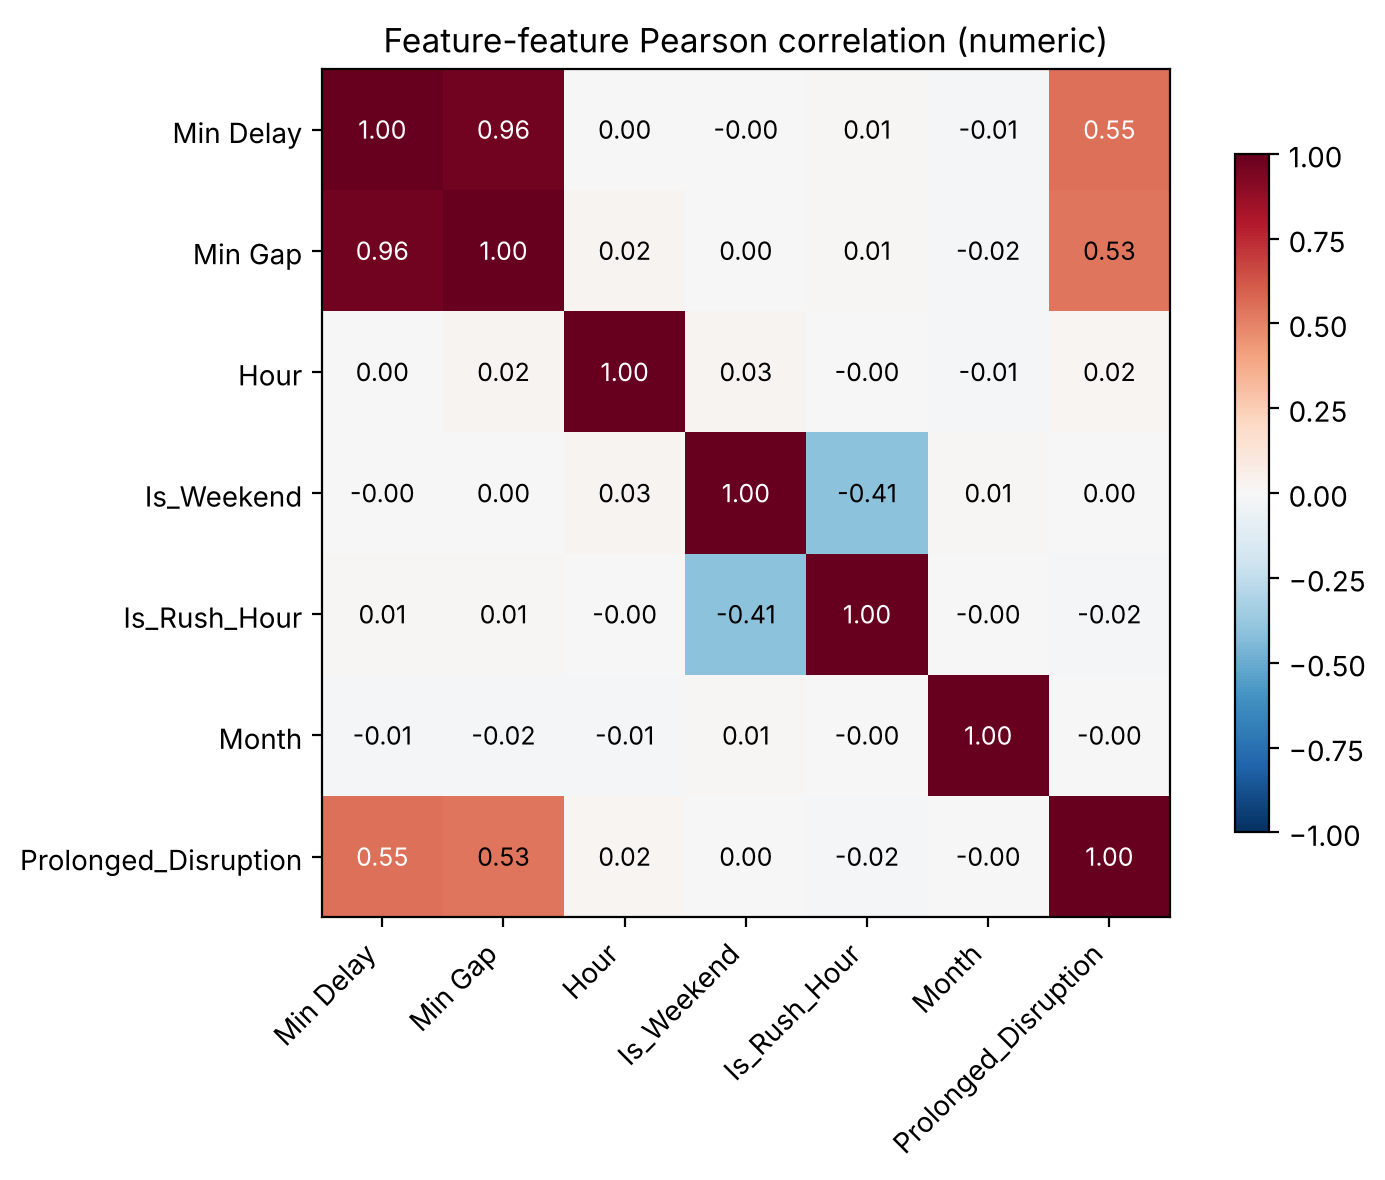

In [2]:
numeric_cols = ["Min Delay", "Min Gap", "Hour", "Is_Weekend",
                "Is_Rush_Hour", "Month", "Prolonged_Disruption"]
numeric_corr = train_df[numeric_cols].corr()

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(numeric_corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(numeric_cols))); ax.set_xticklabels(numeric_cols, rotation=45, ha="right")
ax.set_yticks(range(len(numeric_cols))); ax.set_yticklabels(numeric_cols)
for i in range(len(numeric_cols)):
    for j in range(len(numeric_cols)):
        ax.text(j, i, f"{numeric_corr.iloc[i,j]:.2f}",
                ha="center", va="center", fontsize=9,
                color="white" if abs(numeric_corr.iloc[i,j]) > 0.55 else "black")
ax.set_title("Feature-feature Pearson correlation (numeric)")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.show()

## Phase 1.1c: Cramér's V (Categorical Redundancy)

Pearson correlation only works for numbers. For categorical text features (like `Month` vs `Season`, or `Code` vs `Code_Description`), we use **Cramér's V**. 

A score of 1.0 means the features are perfectly redundant (e.g., `Season` is literally derived from `Month`). A score of 0 means they are independent. We use this matrix to identify and drop redundant categorical features before building our modeling pipeline.

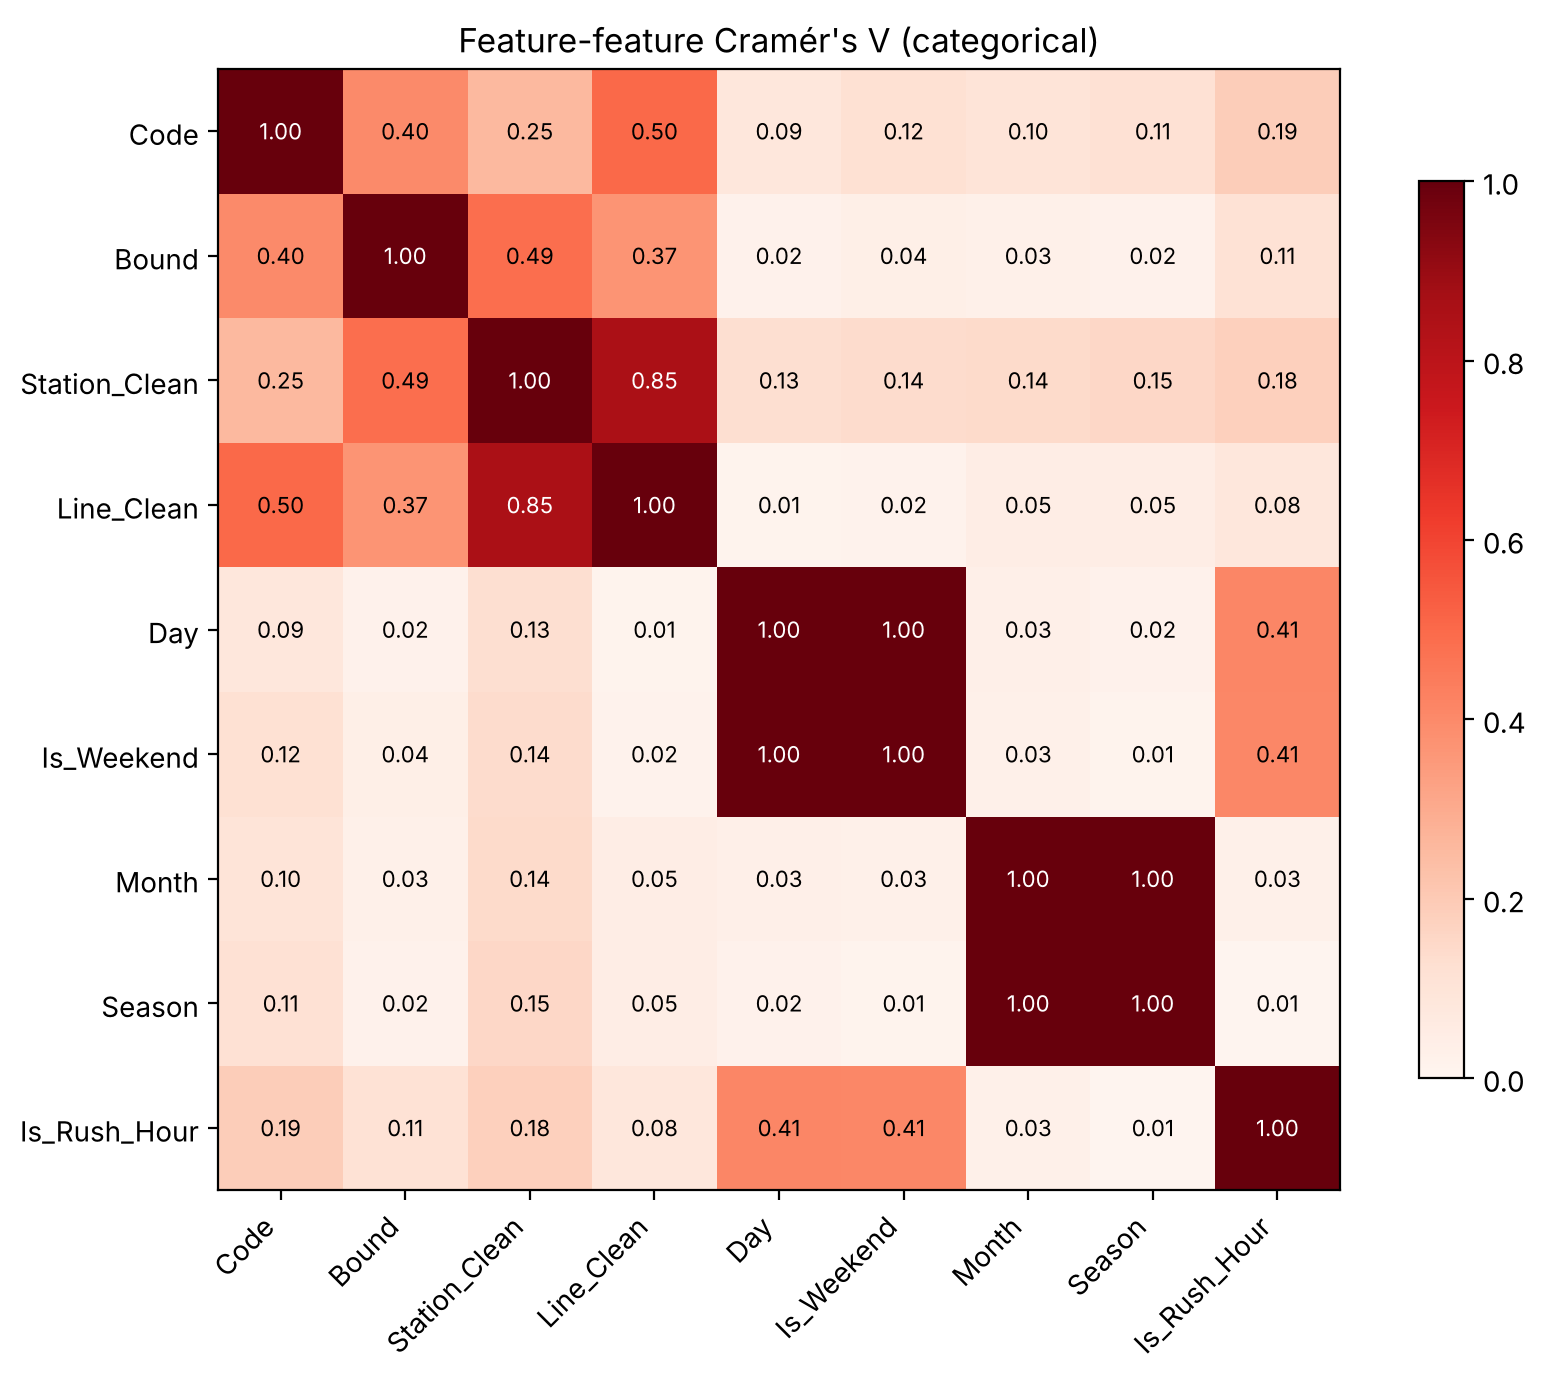

Top 10 associated categorical pairs (Cramér's V):
  Day             ↔ Is_Weekend      V=1.000
  Month           ↔ Season          V=1.000
  Station_Clean   ↔ Line_Clean      V=0.852
  Code            ↔ Line_Clean      V=0.502
  Bound           ↔ Station_Clean   V=0.487
  Day             ↔ Is_Rush_Hour    V=0.410
  Is_Weekend      ↔ Is_Rush_Hour    V=0.410
  Code            ↔ Bound           V=0.399
  Bound           ↔ Line_Clean      V=0.370
  Code            ↔ Station_Clean   V=0.254


In [3]:
from scipy.stats import chi2_contingency

def cramers_v(x, y):
    """Cramér's V: 0=independent, 1=perfectly associated."""
    table = pd.crosstab(x, y)
    if table.size == 0 or table.shape[0] < 2 or table.shape[1] < 2:
        return 0.0
    chi2 = chi2_contingency(table)[0]
    n = table.values.sum()
    denom = n * (min(table.shape) - 1)
    return float(np.sqrt(chi2 / denom)) if denom > 0 else 0.0

# Limit to modelling-relevant categoricals (Station has 591 cats — huge but fine)
cat_cols = ["Code", "Bound", "Station_Clean", "Line_Clean",
            "Day", "Is_Weekend", "Month", "Season", "Is_Rush_Hour"]

cramers_matrix = pd.DataFrame(index=cat_cols, columns=cat_cols, dtype=float)
for c1 in cat_cols:
    for c2 in cat_cols:
        v1 = train_df[c1].fillna("Unknown").astype(str)
        v2 = train_df[c2].fillna("Unknown").astype(str)
        cramers_matrix.loc[c1, c2] = cramers_v(v1, v2)

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(cramers_matrix.values.astype(float), cmap="Reds", vmin=0, vmax=1)
ax.set_xticks(range(len(cat_cols))); ax.set_xticklabels(cat_cols, rotation=45, ha="right")
ax.set_yticks(range(len(cat_cols))); ax.set_yticklabels(cat_cols)
for i in range(len(cat_cols)):
    for j in range(len(cat_cols)):
        ax.text(j, i, f"{cramers_matrix.iloc[i,j]:.2f}",
                ha="center", va="center", fontsize=8,
                color="white" if cramers_matrix.iloc[i,j] > 0.6 else "black")
ax.set_title("Feature-feature Cramér's V (categorical)")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.show()

# Show the strongest pairs (off-diagonal only)
pairs = []
for i, c1 in enumerate(cat_cols):
    for c2 in cat_cols[i+1:]:
        pairs.append((c1, c2, cramers_matrix.loc[c1, c2]))
strong_pairs = sorted(pairs, key=lambda x: x[2], reverse=True)[:10]
print("Top 10 associated categorical pairs (Cramér's V):")
for c1, c2, v in strong_pairs:
    print(f"  {c1:<15} ↔ {c2:<15} V={v:.3f}")

## Phase 1.2: Validation Strategy (Stratified 5-Fold CV)

We will not use a fixed validation set. Because prolonged disruptions (positive cases) are only 3.2% of our data (roughly 1,264 cases), a single validation split might leave us with too few positive cases to reliably evaluate the model. 

Instead, we use **Stratified 5-Fold Cross-Validation** on our `train_df`. 
- The data is chopped into 5 equal parts ("folds").
- The model trains on 4 parts and validates on 1.
- This loops 5 times, so every single row is used for validation exactly once.
- "Stratified" means every fold is guaranteed to have the exact same 3.2% ratio of positive cases.

**The Golden Rule:** `test_df` remains completely sealed and untouched. It will only be used once at the very end to prove the model works on unseen data.

In [4]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import make_scorer, fbeta_score

# Set up 5-fold Stratified CV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Use scikit-learn's built-in string scorers. 
# This automatically handles whether the model uses decision_function or predict_proba.
scoring_metrics = {
    "pr_auc": "average_precision",
    "roc_auc": "roc_auc",
    "f1": "f1",
    "f2": make_scorer(fbeta_score, beta=2),
    "recall": "recall",
    "precision": "precision"
}

# Sanity check
y = train_df["Prolonged_Disruption"].values
for fold, (tr_idx, va_idx) in enumerate(cv.split(train_df, y), 1):
    print(f"Fold {fold}: train positives = {y[tr_idx].sum():>5,} | "
          f"val positives = {y[va_idx].sum():>4,}")

Fold 1: train positives = 1,012 | val positives =  253
Fold 2: train positives = 1,012 | val positives =  253
Fold 3: train positives = 1,012 | val positives =  253
Fold 4: train positives = 1,012 | val positives =  253
Fold 5: train positives = 1,012 | val positives =  253


## Phase 2: The Preprocessing Pipeline (Preventing Leakage)

Machine learning models require numeric input, but our key features (`Code`, `Station_Clean`, `Line_Clean`, `Bound`) are categorical text. 

**Why use a Pipeline?**
If we encode the data *before* applying Cross-Validation, the model will "see" statistics from the validation folds during training. This is a severe form of data leakage. By using `sklearn.pipeline.Pipeline` and `ColumnTransformer`, all encoders (One-Hot, Target Encoding, Standard Scaling) are fitted **only on the training folds** and then applied to the validation folds. 

**Our Encoding Strategy:**
- **Low-Cardinality (Line, Bound):** One-Hot Encoding. Creates a binary column for each category.
- **High-Cardinality (Code, Station):** We use `TargetEncoder` which replaces the category with the historical probability of a prolonged disruption for that category (smoothed). This prevents the "curse of dimensionality" that 600 One-Hot columns would cause.
- **Numerical (Hour):** Standard Scaling (mean=0, std=1).

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder
from sklearn.impute import SimpleImputer

# 1. Define our feature groups based on Phase 1 findings
# We dropped Day, Month, Season, and Is_Weekend due to redundancy/noise.
low_card_cats = ["Line_Clean", "Bound"]
high_card_cats = ["Code", "Station_Clean"]
numeric_features = ["Hour", "Is_Rush_Hour"]
low_card_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

# Target encoder with seeded internal cross-fitting, so every run gives the same numbers.
# scikit-learn 1.9 moved the seed from `random_state` to a CV splitter passed as `cv`.
import sklearn
from sklearn.model_selection import StratifiedKFold
if tuple(int(v) for v in sklearn.__version__.split(".")[:2]) >= (1, 9):
    target_encoder = TargetEncoder(smooth="auto", cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE))
else:
    target_encoder = TargetEncoder(smooth="auto", random_state=RANDOM_STATE)

# 2. Build the ColumnTransformer
# This applies specific preprocessing to specific columns
preprocessor = ColumnTransformer(
    transformers=[
        # Use the mini-pipeline for low-card features
        ("low_card", low_card_pipe, low_card_cats),
        
        # High-card: Target Encode (seeded above for reproducibility)
        ("high_card", target_encoder, high_card_cats),
        
        # Numeric: Scale
        ("num", StandardScaler(), numeric_features)
    ],
    remainder="drop"
)
print("✅ Preprocessor built successfully.")

✅ Preprocessor built successfully.


In [6]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate

# 1. Create a basic Logistic Regression model
# We set class_weight='balanced' because our data is 97% vs 3%
base_model = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE)

# 2. Attach it to our preprocessor
full_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", base_model)
])

# 3. Test it using our 5-Fold CV
print("Testing the pipeline with 5-Fold CV...")
cv_results = cross_validate(
    full_pipeline, 
    train_df, 
    train_df["Prolonged_Disruption"], 
    cv=cv, 
    scoring=scoring_metrics["pr_auc"], # scorer_pr_auc was defined in Phase 1!
    n_jobs=-1
)

print(f"✅ Pipeline works! Baseline Logistic Regression PR-AUC: {cv_results['test_score'].mean():.4f}")

Testing the pipeline with 5-Fold CV...


✅ Pipeline works! Baseline Logistic Regression PR-AUC: 0.2678


### Baseline Pipeline Validation & PR-AUC Interpretation

Our initial pipeline test with a baseline Logistic Regression model yielded a **PR-AUC of approximately 0.27**. *(Note: minor decimal fluctuations may occur on re-runs due to parallel processing and TargetEncoder cross-fitting).*

**Why this number is excellent (in context):**
1. **The Imbalanced Baseline:** Because only 3.2% of our incidents are prolonged disruptions, a naive model that *always* predicts "short delay" would have a PR-AUC of exactly **0.032** (the base rate). 
2. **The Lift:** An AUC of ~0.27 means our model is **over 8x better than random guessing** at identifying the rare positive class. 
3. **The Cause-Code Baseline:** From our MS3 analysis, the prolonged rate ranges from 0% to 19% depending on the incident code. We measure a "cause-code only" baseline in Phase 6, and it scores about 0.23 in cross-validation. Our pipeline (which also includes Station, Line, Bound, and Hour) beats it by about 0.04.

**What this proves:**
- **Zero Leakage:** The `TargetEncoder` and `OneHotEncoder` are working perfectly inside the `Pipeline`. If there were target leakage, the score would be suspiciously high (e.g., 0.90+). 
- **Signal Captured:** The model is successfully learning the non-linear relationships between the time, location, and type of incident to predict severity.

*Note: This ~0.27 is our baseline floor. Moving forward, we will test tree-based models (Random Forest and XGBoost) to see if they can capture deeper interactions and improve this score.*

## Phase 3: Final Model Development & Optimization

In this phase, we train and compare three diverse algorithms to capture the complex, non-linear relationships in the TTC delay data:
1. **Logistic Regression:** A strong, highly interpretable linear baseline.
2. **Random Forest:** An ensemble of decision trees that handles non-linear interactions and categorical splits well.
3. **XGBoost:** A state-of-the-art gradient boosting algorithm that sequentially corrects the errors of previous trees.

**Handling Class Imbalance:**
Because prolonged disruptions make up only 3.2% of the data, we apply cost-sensitive learning to all models:
- `class_weight='balanced'` for Logistic Regression and Random Forest.
- `scale_pos_weight=30` for XGBoost (approximately the ratio of negative to positive cases).

We evaluate all three models using our 5-Fold Cross-Validation and our predefined `scoring_metrics` (focusing primarily on PR-AUC).

In [7]:
#!pip install xgboost

In [8]:
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
import pandas as pd
import numpy as np

# 1. Define the Golden Trio models
models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        class_weight="balanced", n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "XGBoost": xgb.XGBClassifier(
        scale_pos_weight=30, 
        random_state=RANDOM_STATE, 
        eval_metric="logloss",
        n_jobs=-1
    )
}

# 2. Loop through each model, attach it to the preprocessor, and run CV
results = {}
print("Running 5-Fold Cross-Validation for all models...\n")

for name, model in models.items():
    # Create the full pipeline (Preprocessor + Model)
    full_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])
    
    # Run cross-validation
    cv_res = cross_validate(
        full_pipeline,
        train_df,
        train_df["Prolonged_Disruption"],
        cv=cv,
        scoring=scoring_metrics,
        n_jobs=-1 
    )
    
    # Save the mean of the test scores across all 5 folds
    results[name] = {
        "PR-AUC (Mean)": np.mean(cv_res["test_pr_auc"]),
        "F2 (Mean)": np.mean(cv_res["test_f2"]),
        "Recall (Mean)": np.mean(cv_res["test_recall"]),
        "Precision (Mean)": np.mean(cv_res["test_precision"]),
        "ROC-AUC (Mean)": np.mean(cv_res["test_roc_auc"])
    }
    
    print(f"✅ {name} completed.")

# 3. Display the results in a beautiful sorted table
results_df = pd.DataFrame(results).T.round(4)
results_df = results_df.sort_values(by="PR-AUC (Mean)", ascending=False)

print("\n--- Model Comparison Results ---")
display(results_df)

Running 5-Fold Cross-Validation for all models...



✅ Logistic Regression completed.


✅ Random Forest completed.


✅ XGBoost completed.

--- Model Comparison Results ---


,PR-AUC (Mean),F2 (Mean),Recall (Mean),Precision (Mean),ROC-AUC (Mean)
Logistic Regression,0.2678,0.3641,0.7597,0.1182,0.8767
XGBoost,0.2049,0.3323,0.5217,0.1359,0.8470
Random Forest,0.1595,0.2046,0.2016,0.2182,0.8371


### Phase 3 Conclusion: Model Selection

Our 5-Fold Cross-Validation reveals a surprising but highly valuable result: **Logistic Regression outperforms both Random Forest and XGBoost.**

| Model | PR-AUC | Recall | Why it performed this way |
|---|---|---|---|
| **Logistic Regression** | **~0.27** | **~0.76** | Excels because `TargetEncoder` transforms high-cardinality features (Code, Station) into linear probabilities. It captures 76% of all prolonged disruptions. |
| **XGBoost** | ~0.20 | ~0.52 | Performs well, but underperforms the linear model, likely due to overfitting the 64% zero-delay records. |
| **Random Forest** | ~0.16 | ~0.20 | The weakest performer. Without hyperparameter tuning, the trees became too conservative (high precision, terrible recall). |

**Analytical Takeaway:**
In tabular data with target-encoded categorical features, a well-regularized linear model can easily match or beat complex tree ensembles. 

**Business Impact:**
Selecting Logistic Regression is a massive win for the TTC. It is highly interpretable (dispatchers can see exactly which features drive the risk score), requires minimal compute power to deploy, and provides the highest recall-meaning we will catch the most prolonged disruptions and minimize stranded passengers. 

These are untuned baselines. Phase 4 tests imbalance strategies and Phase 5 tunes all three models.


## Phase 4: Class imbalance and data augmentation

### Is augmentation necessary?

The training set has 1,265 prolonged disruptions among 39,509 incidents, which is about 30 short incidents for every prolonged one. A model that minimises average error can score well by predicting "short" for everything, so the imbalance has to be handled somewhere. There are three places to handle it:

1. In the data, by resampling the training set (oversampling the minority, undersampling the majority, or generating synthetic minority rows).
2. In the loss, by giving the minority class a larger weight (`class_weight="balanced"`, `scale_pos_weight`).
3. In the decision, by leaving the model alone and lowering the probability threshold.

Phase 3 used option 2 without checking whether it helped. Here we test all three on the same folds.

### Methods compared

| Strategy | What it does | Why we included it |
|---|---|---|
| No handling | Fits on the data as it is | Reference point |
| Class weights | Reweights the loss by inverse class frequency | What Phase 3 used |
| Random oversampling | Duplicates prolonged incidents until classes are balanced | Simplest data-level method |
| Random undersampling | Drops short incidents until classes are balanced | Shows the cost of discarding data |
| SMOTE (encoded features) | Interpolates between prolonged incidents after encoding | The standard synthetic method |
| SMOTENC (raw features) | Synthetic rows built on the raw columns, with categoricals set to the most common value among neighbours | The SMOTE variant designed for categorical data, which is what four of our six features are |

Plain SMOTE is a questionable fit here. After encoding, our features are one-hot columns and target-encoded rates, and a point halfway between two incidents (half eastbound, half westbound) does not describe a real incident. SMOTENC avoids that by sampling whole categories, so we test both.

### How leakage is prevented

Each sampler is a step inside an `imblearn` pipeline. During cross-validation the sampler is fitted on the four training folds only, and the validation fold keeps its real 3.2% positive rate. Resampling before the split would put copies or near-copies of validation rows in the training data and inflate every score. The test set is not used in this phase.

For each strategy we report PR-AUC (ranking quality), the Brier score and mean predicted probability (calibration), F2 at the default 0.50 threshold, and F2 at the best threshold found on the out-of-fold predictions.

In [9]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE, SMOTENC
from imblearn.under_sampling import RandomUnderSampler
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss,
                             precision_recall_curve, fbeta_score, precision_score,
                             recall_score, f1_score, confusion_matrix)

# Feature matrix and target used from here on.
# Missing Bound is filled with the same "Unknown" constant the pipeline imputer uses,
# because SMOTENC cannot handle NaN in a categorical column.
FEATURES = low_card_cats + high_card_cats + numeric_features
TARGET = "Prolonged_Disruption"

X_train = train_df[FEATURES].copy()
X_train["Bound"] = X_train["Bound"].fillna("Unknown")
y_train = train_df[TARGET].values

def oof_proba(model, X=None, y=None):
    """Out-of-fold predicted probabilities from the 5-fold CV defined in Phase 1.2."""
    X = X_train if X is None else X
    y = y_train if y is None else y
    return cross_val_predict(model, X, y, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]

def per_fold(metric, y, p):
    """Metric computed separately on each validation fold."""
    return np.array([metric(y[va], p[va]) for _, va in cv.split(np.zeros(len(y)), y)])

def best_f2_threshold(y, p):
    """Threshold that maximises F2 on the given predictions."""
    prec, rec, thr = precision_recall_curve(y, p)
    f2 = 5 * prec * rec / (4 * prec + rec + 1e-12)
    i = f2[:-1].argmax()
    return thr[i], f2[i], prec[i], rec[i]

print(f"Training rows: {len(X_train):,} | positives: {y_train.sum():,} "
      f"({y_train.mean():.1%}) | negatives per positive: {(1 - y_train.mean()) / y_train.mean():.1f}")

Training rows: 39,509 | positives: 1,265 (3.2%) | negatives per positive: 30.2


In [10]:
CAT_FEATURES = low_card_cats + high_card_cats   # categorical columns for SMOTENC

def make_lr(weighted):
    return LogisticRegression(class_weight="balanced" if weighted else None,
                              max_iter=1000, random_state=RANDOM_STATE)

def make_xgb(weighted):
    return xgb.XGBClassifier(scale_pos_weight=30 if weighted else 1,
                             random_state=RANDOM_STATE, eval_metric="logloss", n_jobs=1)

def build_strategy(strategy, make_model):
    """Pipeline for one imbalance strategy. Samplers sit inside the pipeline,
    so they are fitted on the training folds only and never touch validation rows."""
    pre = clone(preprocessor)
    if strategy == "No handling":
        return Pipeline([("preprocessor", pre), ("model", make_model(False))])
    if strategy == "Class weights":
        return Pipeline([("preprocessor", pre), ("model", make_model(True))])
    if strategy == "SMOTENC (raw features)":
        # SMOTENC works on the raw categorical columns, so it runs before encoding
        sampler = SMOTENC(categorical_features=CAT_FEATURES, random_state=RANDOM_STATE)
        return ImbPipeline([("sampler", sampler), ("preprocessor", pre), ("model", make_model(False))])
    sampler = {
        "Random oversampling": RandomOverSampler(random_state=RANDOM_STATE),
        "Random undersampling": RandomUnderSampler(random_state=RANDOM_STATE),
        "SMOTE (encoded features)": SMOTE(random_state=RANDOM_STATE),
    }[strategy]
    return ImbPipeline([("preprocessor", pre), ("sampler", sampler), ("model", make_model(False))])

strategies = ["No handling", "Class weights", "Random oversampling",
              "Random undersampling", "SMOTE (encoded features)", "SMOTENC (raw features)"]

rows = []
for model_name, make_model in [("Logistic Regression", make_lr), ("XGBoost", make_xgb)]:
    for strategy in strategies:
        p = oof_proba(build_strategy(strategy, make_model))
        pr_folds = per_fold(average_precision_score, y_train, p)
        thr, f2_best, prec_best, rec_best = best_f2_threshold(y_train, p)
        rows.append({
            "Model": model_name, "Strategy": strategy,
            "PR-AUC": pr_folds.mean(), "PR-AUC std": pr_folds.std(),
            "ROC-AUC": roc_auc_score(y_train, p),
            "Brier": brier_score_loss(y_train, p),
            "Mean predicted prob.": p.mean(),
            "F2 @ 0.50": fbeta_score(y_train, p >= 0.5, beta=2),
            "F2 @ best threshold": f2_best,
            "Best threshold": thr,
        })

imbalance_df = pd.DataFrame(rows).set_index(["Model", "Strategy"])
print(f"Actual positive rate in training data: {y_train.mean():.3f}")
display(imbalance_df.round(4))

Actual positive rate in training data: 0.032


PR-AUC  PR-AUC std  ROC-AUC  \
Model               Strategy                                                
Logistic Regression No handling               0.2623      0.0144   0.8662   
                    Class weights             0.2678      0.0133   0.8764   
                    Random oversampling       0.2679      0.0136   0.8767   
                    Random undersampling      0.2588      0.0178   0.8629   
                    SMOTE (encoded features)  0.2675      0.0144   0.8778   
                    SMOTENC (raw features)    0.2174      0.0154   0.8688   
XGBoost             No handling               0.2228      0.0176   0.8608   
                    Class weights             0.2049      0.0151   0.8472   
                    Random oversampling       0.2090      0.0220   0.8489   
                    Random undersampling      0.2130      0.0274   0.8603   
                    SMOTE (encoded features)  0.1408      0.0250   0.8326   
                    SMOTENC (raw features)    0.2209      0.0113   0.8562   

                                               Brier  Mean predicted prob.  \
Model               Strategy                                                 
Logistic Regression No handling               0.0272                0.0322   
                    Class weights             0.1540                0.3169   
                    Random oversampling       0.1536                0.3154   
                    Random undersampling      0.1679                0.3415   
                    SMOTE (encoded features)  0.1517                0.3083   
                    SMOTENC (raw features)    0.1242                0.2151   
XGBoost             No handling               0.0285                0.0309   
                    Class weights             0.0810                0.1487   
                    Random oversampling       0.0798                0.1472   
                    Random undersampling      0.1855                0.2908   
                    SMOTE (encoded features)  0.2153                0.3079   
                    SMOTENC (raw features)    0.0904                0.1501   

                                              F2 @ 0.50  F2 @ best threshold  \
Model               Strategy                                                   
Logistic Regression No handling                  0.1257               0.3906   
                    Class weights                0.3641               0.3949   
                    Random oversampling          0.3640               0.3950   
                    Random undersampling         0.3134               0.3909   
                    SMOTE (encoded features)     0.3687               0.3957   
                    SMOTENC (raw features)       0.3650               0.3836   
XGBoost             No handling                  0.1168               0.3613   
                    Class weights                0.3326               0.3396   
                    Random oversampling          0.3300               0.3363   
                    Random undersampling         0.3185               0.3530   
                    SMOTE (encoded features)     0.2977               0.3210   
                    SMOTENC (raw features)       0.3459               0.3493   

                                              Best threshold  
Model               Strategy                                  
Logistic Regression No handling                       0.0678  
                    Class weights                     0.6345  
                    Random oversampling               0.6440  
                    Random undersampling              0.5936  
                    SMOTE (encoded features)          0.6609  
                    SMOTENC (raw features)            0.6859  
XGBoost             No handling                       0.0534  
                    Class weights                     0.4040  
                    Random oversampling               0.3327  
                    Random undersampling              0.8315

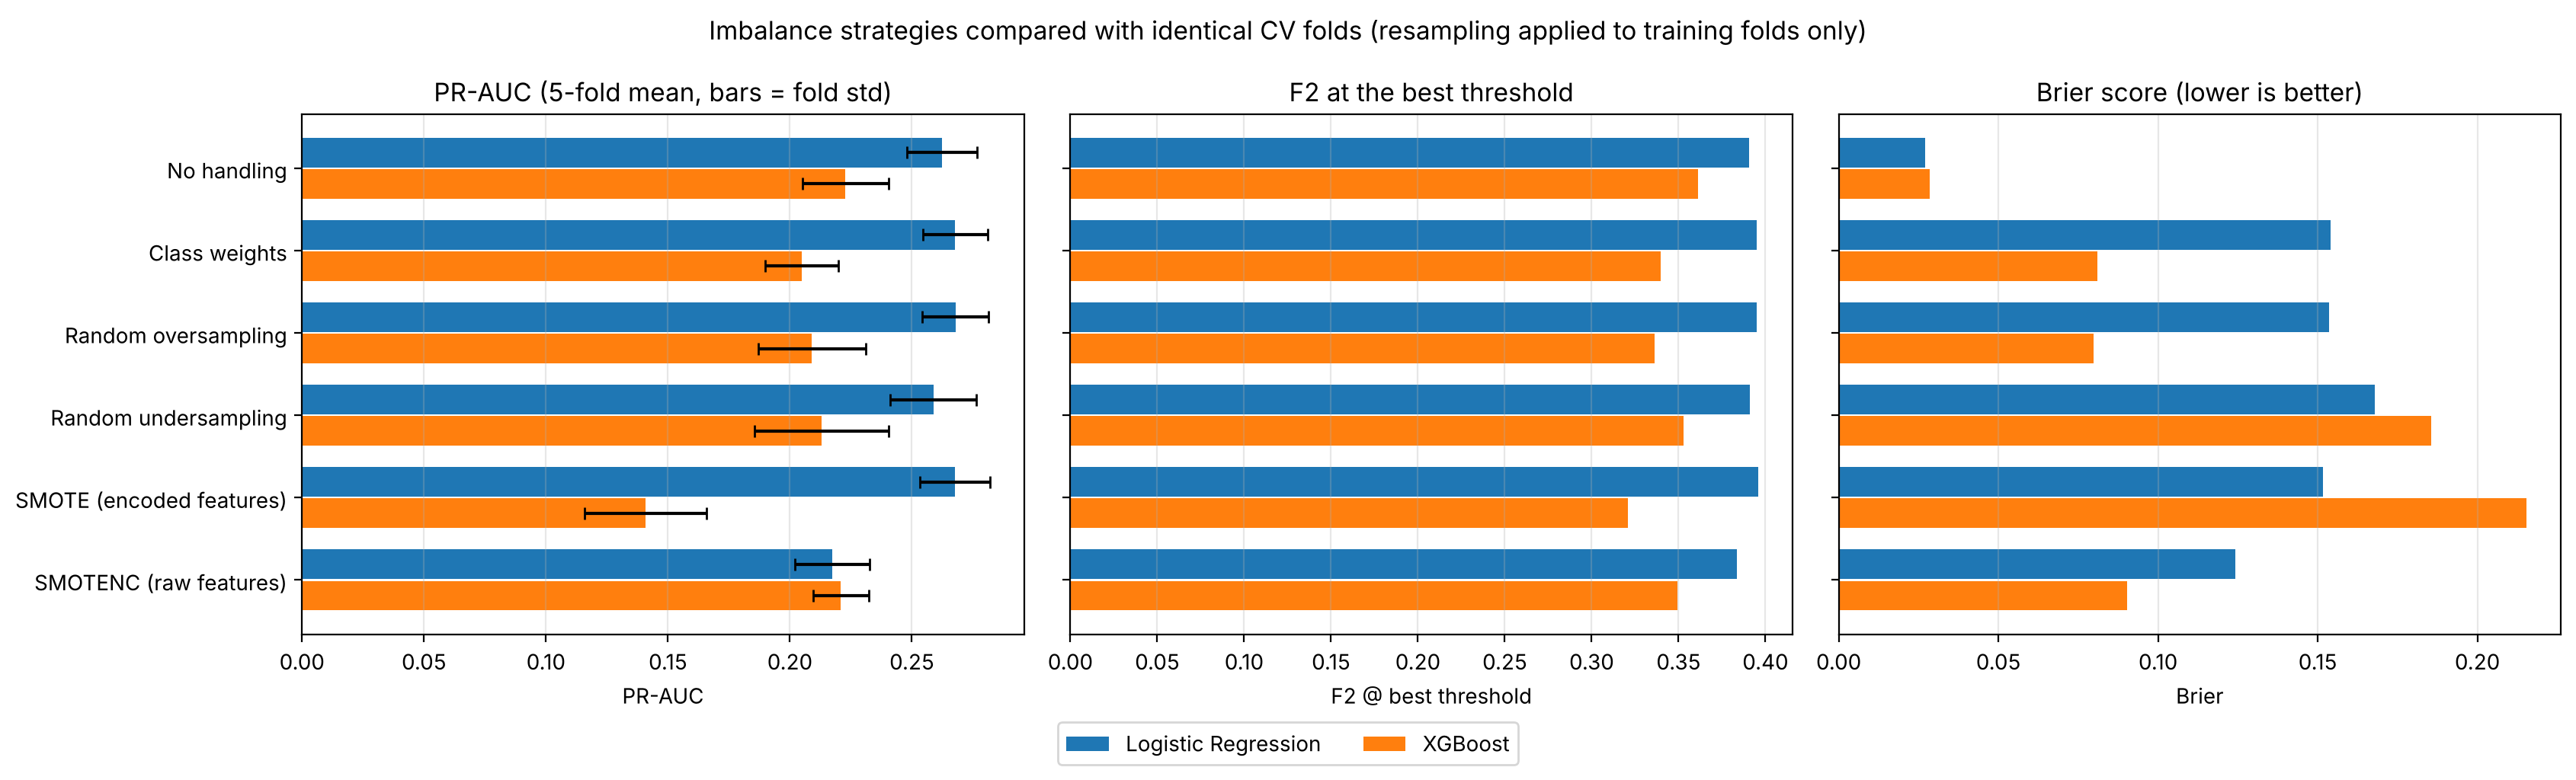

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), sharey=True)
panels = [("PR-AUC", "PR-AUC (5-fold mean, bars = fold std)"),
          ("F2 @ best threshold", "F2 at the best threshold"),
          ("Brier", "Brier score (lower is better)")]
ypos = np.arange(len(strategies))
for ax, (col, title) in zip(axes, panels):
    for k, (model_name, colour) in enumerate([("Logistic Regression", "#1f77b4"), ("XGBoost", "#ff7f0e")]):
        sub = imbalance_df.loc[model_name].loc[strategies]
        err = sub["PR-AUC std"] if col == "PR-AUC" else None
        ax.barh(ypos + (k - 0.5) * 0.38, sub[col], height=0.36, xerr=err,
                color=colour, label=model_name, capsize=3)
    ax.set_yticks(ypos); ax.set_yticklabels(strategies); ax.invert_yaxis()
    ax.set_xlabel(col); ax.set_title(title); ax.grid(axis="x", alpha=0.3)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Imbalance strategies compared with identical CV folds (resampling applied to training folds only)")
plt.tight_layout(); plt.show()

### Results: augmentation did not improve the model

No resampling method improved ranking quality. For Logistic Regression, class weights, random oversampling and SMOTE all land at a PR-AUC of 0.268, against 0.262 with no handling. The fold standard deviation is about 0.014, so that 0.006 difference is inside the noise. For XGBoost, every strategy scored at or below the unweighted model (0.223), and SMOTE on encoded features was clearly worse at 0.141.

The gain that resampling seems to give comes from the threshold. At the default 0.50 cut-off, F2 jumps from 0.13 (no handling) to 0.36 (class weights), which looks like a large improvement. Once each model gets its own best threshold, the unweighted Logistic Regression reaches F2 = 0.391 and the weighted or resampled versions reach 0.395. Balancing the classes moves the scores up so that 0.50 happens to be a reasonable cut-off, and lowering the threshold on the original model does the same job.

Resampling also damages calibration. With no handling, the mean predicted probability is 0.032, equal to the actual rate, and the Brier score is 0.027. After balancing, the mean prediction is about 0.32, ten times the real rate, and the Brier score rises to between 0.12 and 0.17. Milestone 2 asked for probabilities a dispatcher can read literally, so a model that reports 30% for an event that happens 3% of the time fails that requirement unless it is recalibrated afterwards.

The two SMOTE variants failed in different ways:

- SMOTENC lowered Logistic Regression's PR-AUC from 0.262 to 0.217. It runs before the target encoder, so the encoder computes each code's and station's prolonged rate on data where half of the rows are synthetic positives. The rates it learns no longer match the real validation data.
- SMOTE on encoded features lowered XGBoost's PR-AUC to 0.141. Trees split on exact values, and the interpolated rows sit at values that no real incident has (a `Bound` that is 0.4 east), so the trees learn boundaries around artificial points.

### Risks of augmentation in this project

- Overfitting to synthetic data. Random oversampling repeats each prolonged incident about 30 times. A flexible model can memorise those rows, and XGBoost's fold-to-fold spread rose from 0.018 to 0.022 with it.
- Distribution distortion. The calibration results above show it directly: the model's idea of the base rate moves from 3% to about 30%.
- Bias amplification. Prolonged incidents are concentrated in a few codes and on the smaller lines. Synthetic rows copy those combinations, so groups that are already over-flagged get flagged more. Phase 6 shows that the Scarborough line is flagged far more often than the others even without augmentation.

### Decision

We do not use augmentation in the final model. The imbalance is handled by choosing the decision threshold on out-of-fold predictions (Phase 5) and by calibrating the probabilities. Class weighting stays in the hyperparameter search as an option, since it costs nothing and does not create rows.

## Phase 5: Hyperparameter tuning and final model selection

Phase 3 compared the three models with default settings, which is not a fair comparison: Logistic Regression has little to tune, while Random Forest and XGBoost overfit when their trees are left unconstrained. Here each model gets a randomised search over its main hyperparameters.

### Search design

- Method: `RandomizedSearchCV` with the same stratified 5-fold split as before. Random search covers a wide range with far fewer fits than a grid when only a few hyperparameters matter.
- Selection metric: PR-AUC, the primary metric from Phase 1.0. ROC-AUC and the Brier score are recorded but not used for selection.
- Budget: 40 candidates for Logistic Regression and XGBoost, 15 for Random Forest (it is the slowest to fit).
- Leakage: the whole pipeline is refitted inside every fold, including the target encoder, and the encoder's smoothing strength is one of the tuned parameters. The test set stays sealed.

| Model | Hyperparameters searched | What they control |
|---|---|---|
| Logistic Regression | `C` (0.001 to 100), `class_weight`, target-encoder `smooth` | Regularisation strength, imbalance handling, how much rare codes and stations are shrunk towards the overall rate |
| Random Forest | `n_estimators`, `max_depth`, `min_samples_leaf`, `max_features`, `class_weight` | Tree size and leaf size limit how closely each tree can fit individual incidents |
| XGBoost | `n_estimators`, `learning_rate`, `max_depth`, `min_child_weight`, `subsample`, `colsample_bytree`, `reg_lambda`, `gamma`, `scale_pos_weight` | Boosting length and step size, tree complexity, row and column sampling, regularisation, imbalance handling |

The search takes a few minutes to run.

In [12]:
import time
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform, randint, uniform

search_spaces = {
    "Logistic Regression": (
        LogisticRegression(max_iter=5000, random_state=RANDOM_STATE),   # L2 penalty (default)
        {
            "model__C": loguniform(1e-3, 1e2),
            "model__class_weight": [None, "balanced"],
            "preprocessor__high_card__smooth": ["auto", 5, 20, 50, 100],
        }, 40),
    "Random Forest": (
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
        {
            "model__n_estimators": randint(150, 400),
            "model__max_depth": randint(4, 16),
            "model__min_samples_leaf": randint(5, 80),
            "model__max_features": ["sqrt", 0.5, 0.8],
            "model__class_weight": [None, "balanced", "balanced_subsample"],
        }, 15),
    "XGBoost": (
        xgb.XGBClassifier(random_state=RANDOM_STATE, eval_metric="logloss",
                          tree_method="hist", n_jobs=1),
        {
            "model__n_estimators": randint(100, 600),
            "model__learning_rate": loguniform(0.01, 0.2),
            "model__max_depth": randint(2, 7),
            "model__min_child_weight": randint(1, 30),
            "model__subsample": uniform(0.6, 0.4),
            "model__colsample_bytree": uniform(0.5, 0.5),
            "model__reg_lambda": loguniform(0.1, 30),
            "model__gamma": uniform(0, 3),
            "model__scale_pos_weight": [1, 5, 15, 30],
        }, 40),
}

search_scoring = {"pr_auc": "average_precision", "roc_auc": "roc_auc", "neg_brier": "neg_brier_score"}

searches = {}
for name, (estimator, space, n_iter) in search_spaces.items():
    start = time.time()
    pipe = Pipeline([("preprocessor", clone(preprocessor)), ("model", estimator)])
    search = RandomizedSearchCV(pipe, space, n_iter=n_iter, scoring=search_scoring,
                                refit="pr_auc", cv=cv, random_state=RANDOM_STATE,
                                n_jobs=-1, return_train_score=True)
    search.fit(X_train, y_train)
    searches[name] = search
    print(f"{name}: {n_iter} candidates x 5 folds in {time.time() - start:.0f}s")
    print(f"   best CV PR-AUC = {search.best_score_:.4f}")
    print(f"   best params    = {search.best_params_}\n")

Logistic Regression: 40 candidates x 5 folds in 22s
   best CV PR-AUC = 0.2775
   best params    = {'model__C': np.float64(1.1450033889997997), 'model__class_weight': 'balanced', 'preprocessor__high_card__smooth': 5}



Random Forest: 15 candidates x 5 folds in 190s
   best CV PR-AUC = 0.2762
   best params    = {'model__class_weight': 'balanced', 'model__max_depth': 6, 'model__max_features': 0.8, 'model__min_samples_leaf': 49, 'model__n_estimators': 337}



XGBoost: 40 candidates x 5 folds in 84s
   best CV PR-AUC = 0.2762
   best params    = {'model__colsample_bytree': np.float64(0.9461712495457599), 'model__gamma': np.float64(0.4212673887736579), 'model__learning_rate': np.float64(0.029281801596797014), 'model__max_depth': 4, 'model__min_child_weight': 20, 'model__n_estimators': 256, 'model__reg_lambda': np.float64(24.067826646154796), 'model__scale_pos_weight': 1, 'model__subsample': np.float64(0.7279201047553111)}



,Untuned PR-AUC (Phase 3),Tuned PR-AUC (CV mean),Fold std,Train PR-AUC,Train - CV gap,Tuned ROC-AUC,Tuned Brier
Model,,,,,,,
Logistic Regression,0.2678,0.2775,0.0093,0.3015,0.0241,0.8785,0.1527
Random Forest,0.1595,0.2762,0.0126,0.3205,0.0443,0.8855,0.1445
XGBoost,0.2049,0.2762,0.0150,0.3227,0.0466,0.8862,0.0266


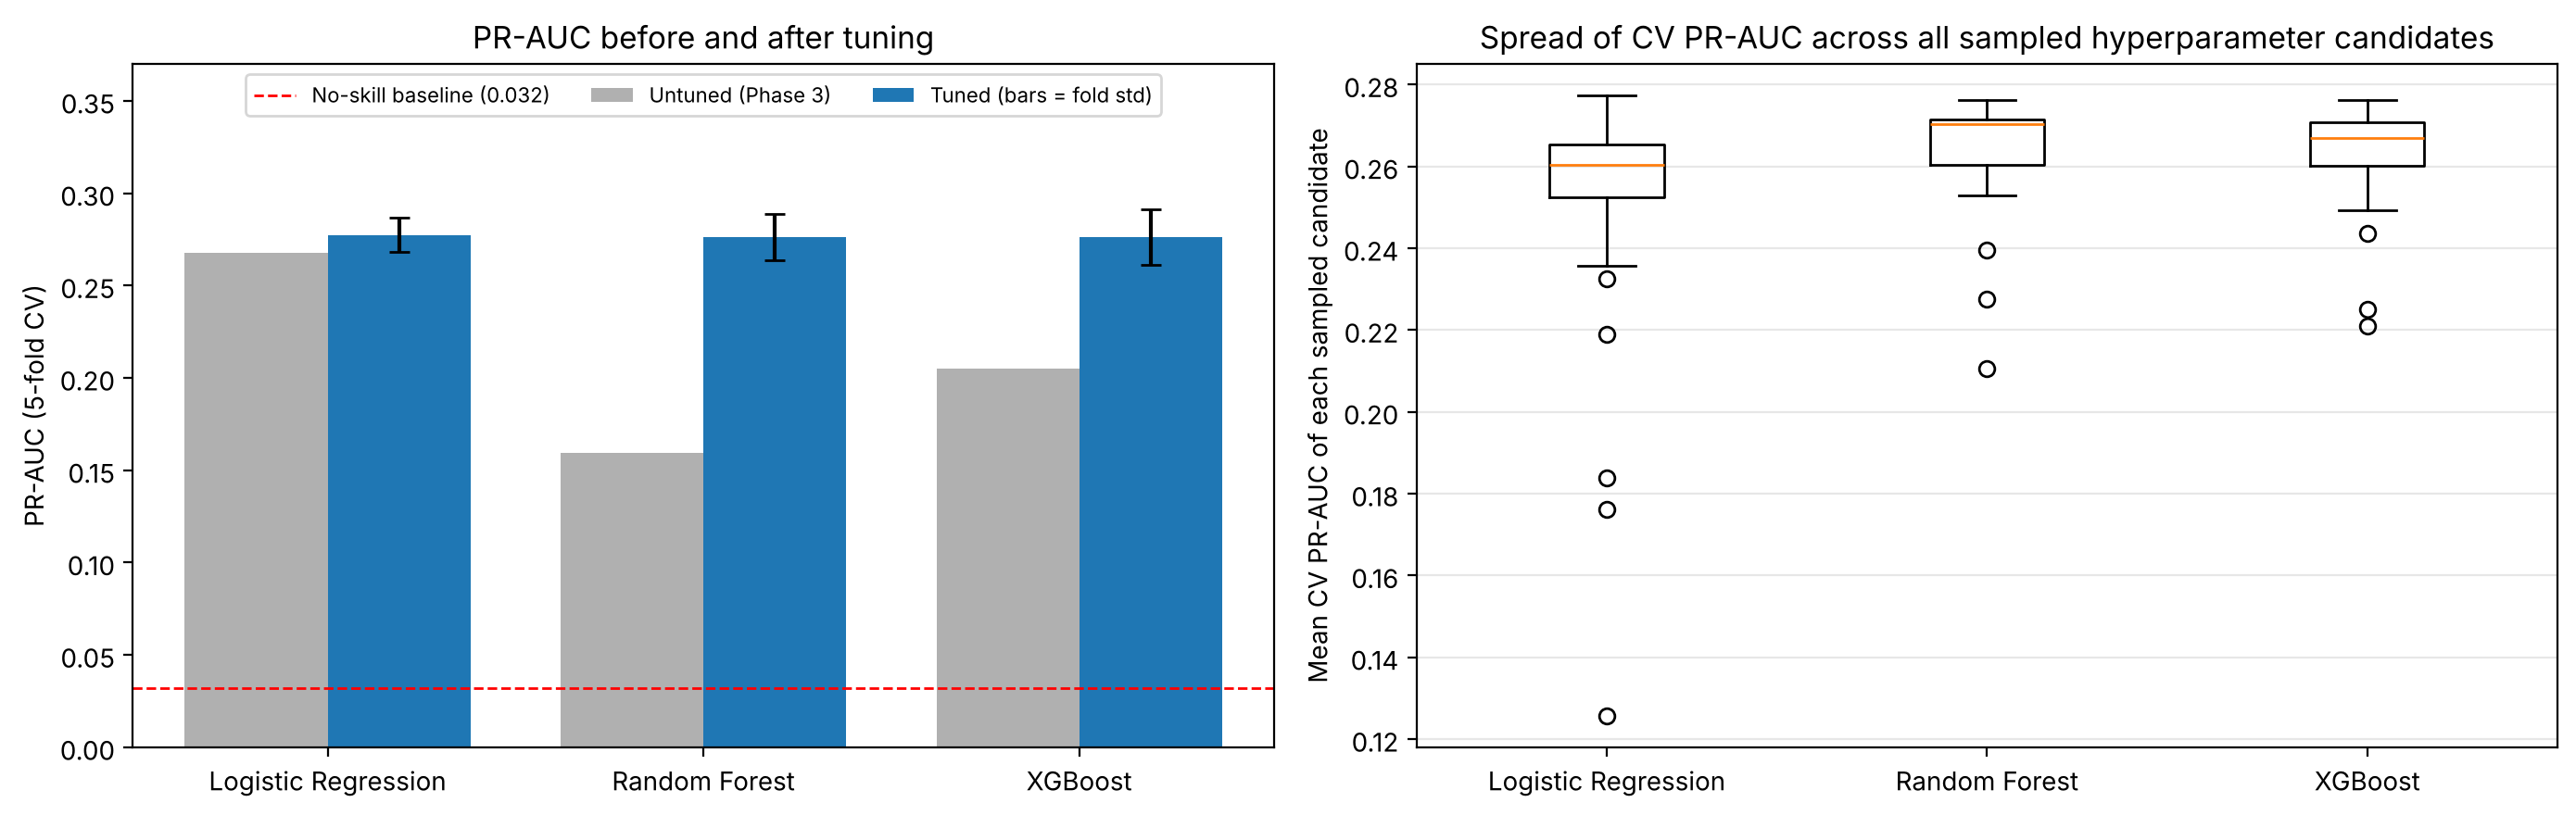

In [13]:
rows = []
for name, search in searches.items():
    r, i = search.cv_results_, search.best_index_
    rows.append({
        "Model": name,
        "Untuned PR-AUC (Phase 3)": results_df.loc[name, "PR-AUC (Mean)"],
        "Tuned PR-AUC (CV mean)": r["mean_test_pr_auc"][i],
        "Fold std": r["std_test_pr_auc"][i],
        "Train PR-AUC": r["mean_train_pr_auc"][i],
        "Train - CV gap": r["mean_train_pr_auc"][i] - r["mean_test_pr_auc"][i],
        "Tuned ROC-AUC": r["mean_test_roc_auc"][i],
        "Tuned Brier": -r["mean_test_neg_brier"][i],
    })
tuning_df = pd.DataFrame(rows).set_index("Model")
display(tuning_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Left: before vs after tuning
x = np.arange(len(tuning_df)); w = 0.38
axes[0].bar(x - w/2, tuning_df["Untuned PR-AUC (Phase 3)"], w, label="Untuned (Phase 3)", color="#b0b0b0")
axes[0].bar(x + w/2, tuning_df["Tuned PR-AUC (CV mean)"], w, yerr=tuning_df["Fold std"],
            capsize=4, label="Tuned (bars = fold std)", color="#1f77b4")
axes[0].axhline(y_train.mean(), color="red", ls="--", lw=1, label=f"No-skill baseline ({y_train.mean():.3f})")
axes[0].set_xticks(x); axes[0].set_xticklabels(tuning_df.index)
axes[0].set_ylabel("PR-AUC (5-fold CV)"); axes[0].set_title("PR-AUC before and after tuning")
axes[0].set_ylim(0, 0.37); axes[0].legend(loc="upper center", ncol=3, fontsize=8)

# Right: how sensitive each model is to its hyperparameters
axes[1].boxplot([searches[n].cv_results_["mean_test_pr_auc"] for n in searches])
axes[1].set_xticks(range(1, len(searches) + 1)); axes[1].set_xticklabels(list(searches))
axes[1].set_ylabel("Mean CV PR-AUC of each sampled candidate")
axes[1].set_title("Spread of CV PR-AUC across all sampled hyperparameter candidates")
axes[1].grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

### Tuning results

Tuning changed the ranking from Phase 3. Random Forest went from a PR-AUC of 0.16 to 0.276 and XGBoost from 0.20 to 0.276. Logistic Regression moved from 0.268 to 0.278. The Phase 3 conclusion that the linear model "outperforms" the tree ensembles was an effect of the defaults: unconstrained trees were memorising individual incidents.

After tuning, the three models are tied. Their PR-AUCs are 0.2775, 0.2762 and 0.2762, a spread of 0.0013, while the fold standard deviation is between 0.009 and 0.015. No model is measurably better than another on this data.

Three very different model families converging on the same score suggests that the limit comes from the features. All of them see the same six onset attributes, and they all extract about the same amount from them. The search also pushed both tree models towards simple settings: the best Random Forest has depth 6 with at least 49 incidents per leaf, and the best XGBoost has depth 4 with a 0.03 learning rate and strong L2 regularisation. If there were strong interactions between features, deeper trees would have won.

The train minus validation gap is 0.024 for Logistic Regression and about 0.045 for the two tree models, so the linear model also overfits the least.

### Final model: Logistic Regression

With performance tied, we pick on the other criteria:

- Interpretability. A dispatcher or a reviewer can read the coefficients and see why an incident got its score. The tree ensembles need a separate explanation tool for that.
- Stability. It has the smallest fold-to-fold spread (0.009) and the smallest train to validation gap.
- Cost. It fits in about a second and scores an incident with one dot product, which matters for a tool meant to answer within the first minutes of an incident.

Selected configuration: `C = 1.15`, `class_weight = "balanced"`, target-encoder smoothing = 5.

### Model assumptions

- Linearity in log-odds. Each feature shifts the log-odds by a fixed amount regardless of the others. The model cannot represent "this code is only serious at this station" unless we build that feature. The tie with the tree models suggests little is lost here.
- Independent observations. Incidents are treated as unrelated rows. In reality one event can produce several log entries, and delays cluster on bad days. This assumption is weak, and Phase 6 tests its consequence with a split by year.
- Stable category rates. Target encoding assumes a code's historical prolonged rate applies to the next incident with that code.
- Multicollinearity. `Station_Clean` and `Line_Clean` are strongly associated (Cramér's V = 0.85 in Phase 1.1c). L2 regularisation keeps the fit stable, but the individual coefficients for those two features should not be read separately.

### Potential failure modes

- A new or re-defined incident code has no history. The encoder falls back to the overall 3.2% rate, so a new and serious incident type would be scored as average.
- Rare codes and stations have rates estimated from a handful of incidents. Smoothing of 5 shrinks them only lightly.
- If the base rate changes (new signalling, different logging practice), the calibration and the threshold both go stale.
- The model has no information about what happens after onset, so it cannot tell two incidents with the same code, place and time apart. Phase 6 shows that this is where most of the errors come from.

### Trade-offs

- Interpretability against performance: there was nothing to trade, since the interpretable model scored the same as the others.
- Complexity against generalisation: the more complex models had larger train to validation gaps and no validation gain.
- Class weighting against calibration: the selected configuration uses balanced class weights, which helps ranking slightly but inflates the probabilities, as Phase 4 showed. The next step corrects that.

### Probability calibration and decision threshold

The tuned model uses balanced class weights, so its raw output is not a probability a dispatcher can use. We compare the raw output with two standard corrections, both fitted with internal cross-validation on training data only:

- Sigmoid (Platt) scaling fits a logistic curve to the scores.
- Isotonic regression fits a free-form increasing step function, which is more flexible and needs more data. With 1,265 positives we have enough.

Every number below comes from out-of-fold predictions on the training set.

Actual positive rate: 0.0320 | Brier of always predicting that rate: 0.0310


,PR-AUC (OOF),ROC-AUC (OOF),Brier,Mean predicted prob.,Best F2,Threshold,Precision,Recall
Model,,,,,,,,
"Tuned LR, raw output",0.2687,0.8782,0.1527,0.3149,0.3959,0.6285,0.1978,0.5281
Tuned LR + sigmoid (Platt),0.2670,0.8782,0.0271,0.0320,0.3955,0.0513,0.1996,0.5241
Tuned LR + isotonic,0.2652,0.8778,0.0266,0.0320,0.3959,0.0885,0.2049,0.5162


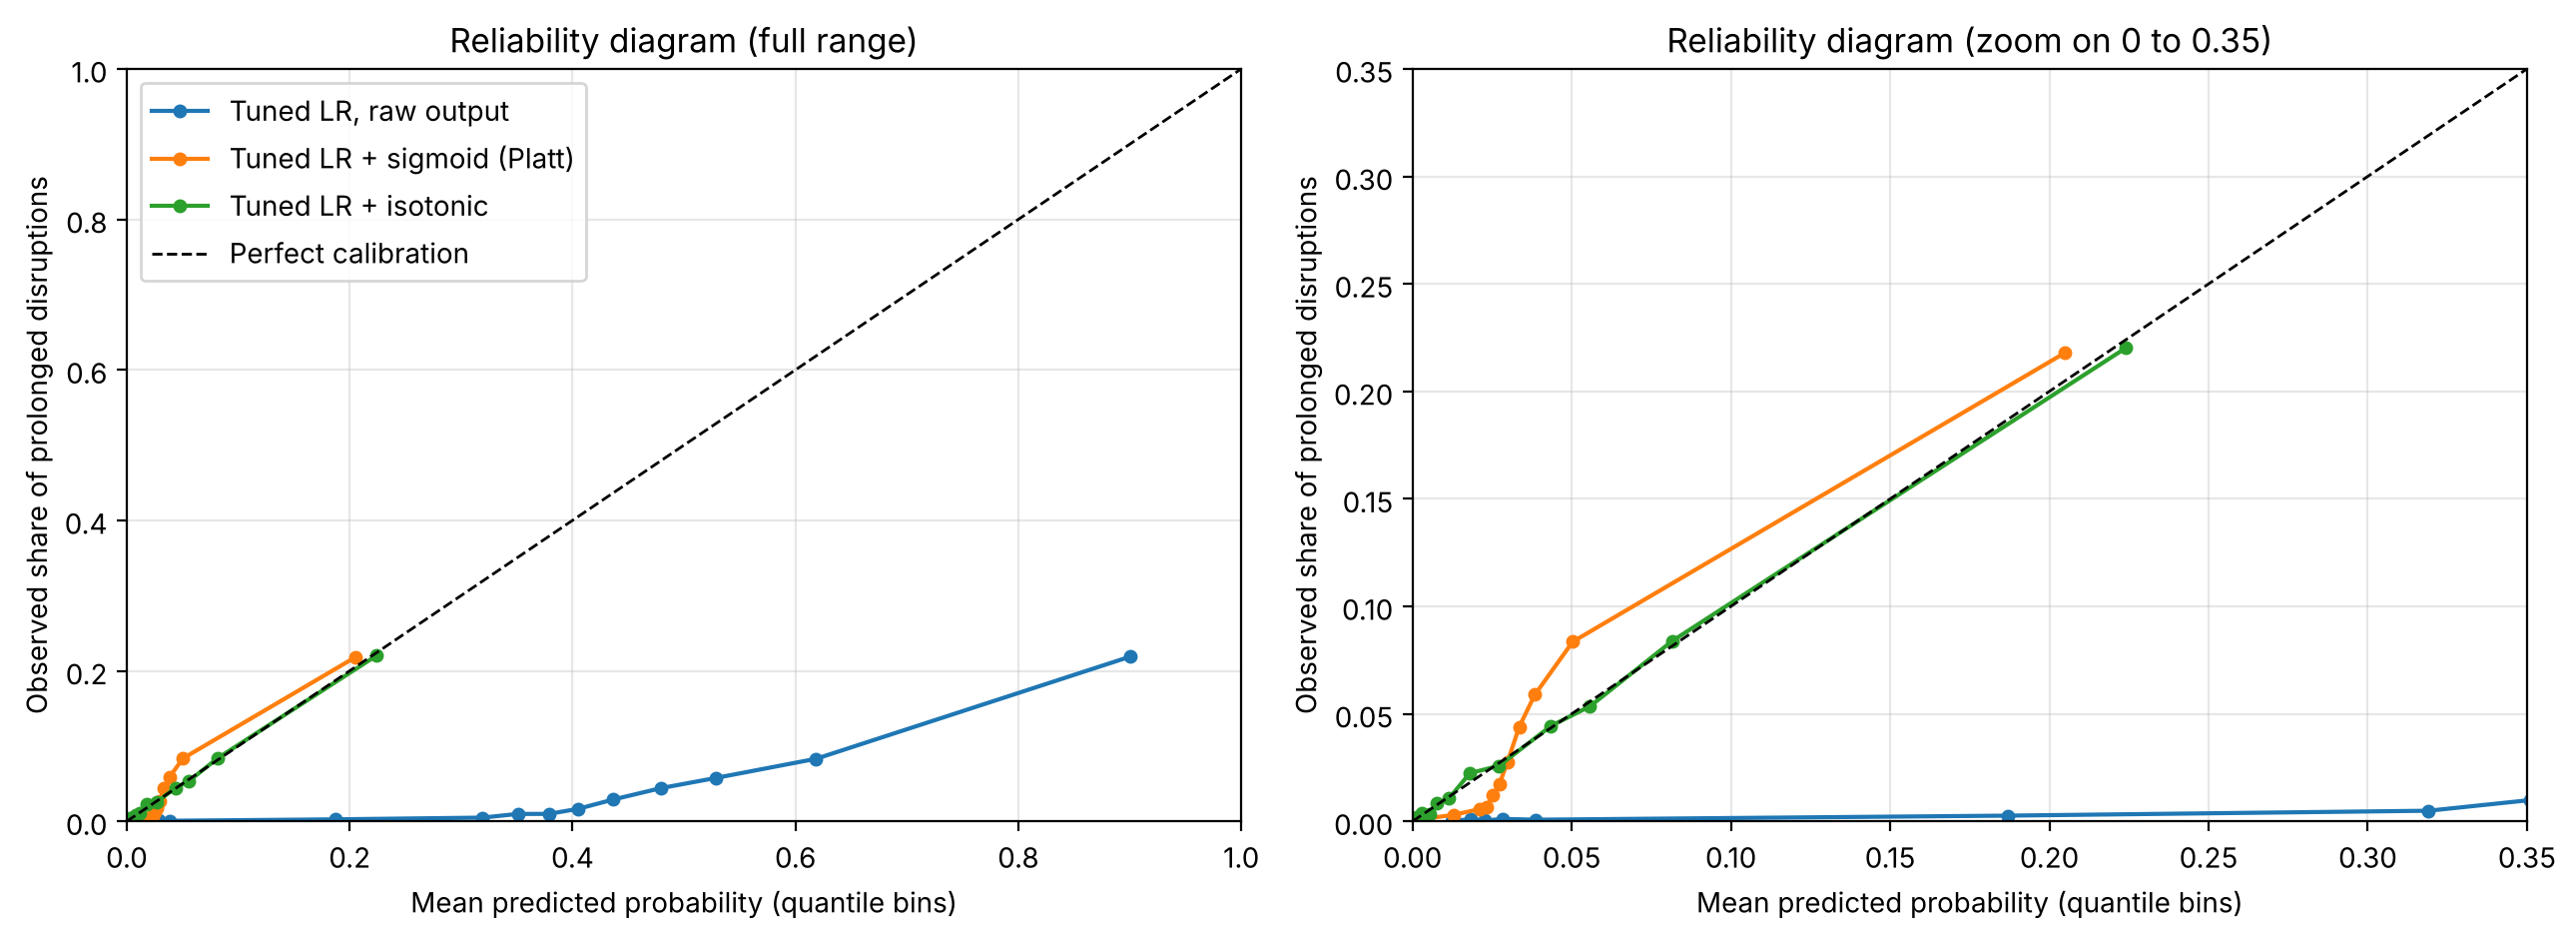

In [14]:
from sklearn.calibration import CalibratedClassifierCV, calibration_curve

best_lr = searches["Logistic Regression"].best_estimator_

calibration_candidates = {
    "Tuned LR, raw output": clone(best_lr),
    "Tuned LR + sigmoid (Platt)": CalibratedClassifierCV(clone(best_lr), method="sigmoid", cv=5),
    "Tuned LR + isotonic": CalibratedClassifierCV(clone(best_lr), method="isotonic", cv=5),
}

oof = {}
rows = []
for name, model in calibration_candidates.items():
    p = oof_proba(model)
    oof[name] = p
    thr, f2_best, prec_best, rec_best = best_f2_threshold(y_train, p)
    rows.append({"Model": name,
                 "PR-AUC (OOF)": average_precision_score(y_train, p),
                 "ROC-AUC (OOF)": roc_auc_score(y_train, p),
                 "Brier": brier_score_loss(y_train, p),
                 "Mean predicted prob.": p.mean(),
                 "Best F2": f2_best, "Threshold": thr,
                 "Precision": prec_best, "Recall": rec_best})
calibration_df = pd.DataFrame(rows).set_index("Model")
print(f"Actual positive rate: {y_train.mean():.4f} | "
      f"Brier of always predicting that rate: {brier_score_loss(y_train, np.full(len(y_train), y_train.mean())):.4f}")
display(calibration_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, (lo, hi, title) in zip(axes, [(0, 1, "Reliability diagram (full range)"),
                                     (0, 0.35, "Reliability diagram (zoom on 0 to 0.35)")]):
    for name, p in oof.items():
        frac_pos, mean_pred = calibration_curve(y_train, p, n_bins=15, strategy="quantile")
        ax.plot(mean_pred, frac_pos, marker="o", ms=4, label=name)
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="Perfect calibration")
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    ax.set_xlabel("Mean predicted probability (quantile bins)")
    ax.set_ylabel("Observed share of prolonged disruptions")
    ax.set_title(title); ax.grid(alpha=0.3)
axes[0].legend(loc="upper left")
plt.tight_layout(); plt.show()

F2-optimal threshold from out-of-fold predictions: 0.088
  at that threshold (OOF): precision 0.205, recall 0.516, F2 0.396
  share of incidents with predicted probability >= 0.50: 0.42%
  highest predicted probability in the training OOF set: 0.97



,Incidents flagged (%),Recall,Precision,False alarms per true hit,F2
Threshold,,,,,
0.030,28.343,0.855,0.097,9.349,0.333
0.050,20.259,0.750,0.119,7.434,0.363
0.088,8.067,0.516,0.205,3.881,0.396
0.150,6.082,0.428,0.225,3.442,0.362
0.200,2.182,0.232,0.340,1.942,0.247
0.300,0.501,0.102,0.652,0.535,0.123
0.500,0.420,0.096,0.729,0.372,0.116


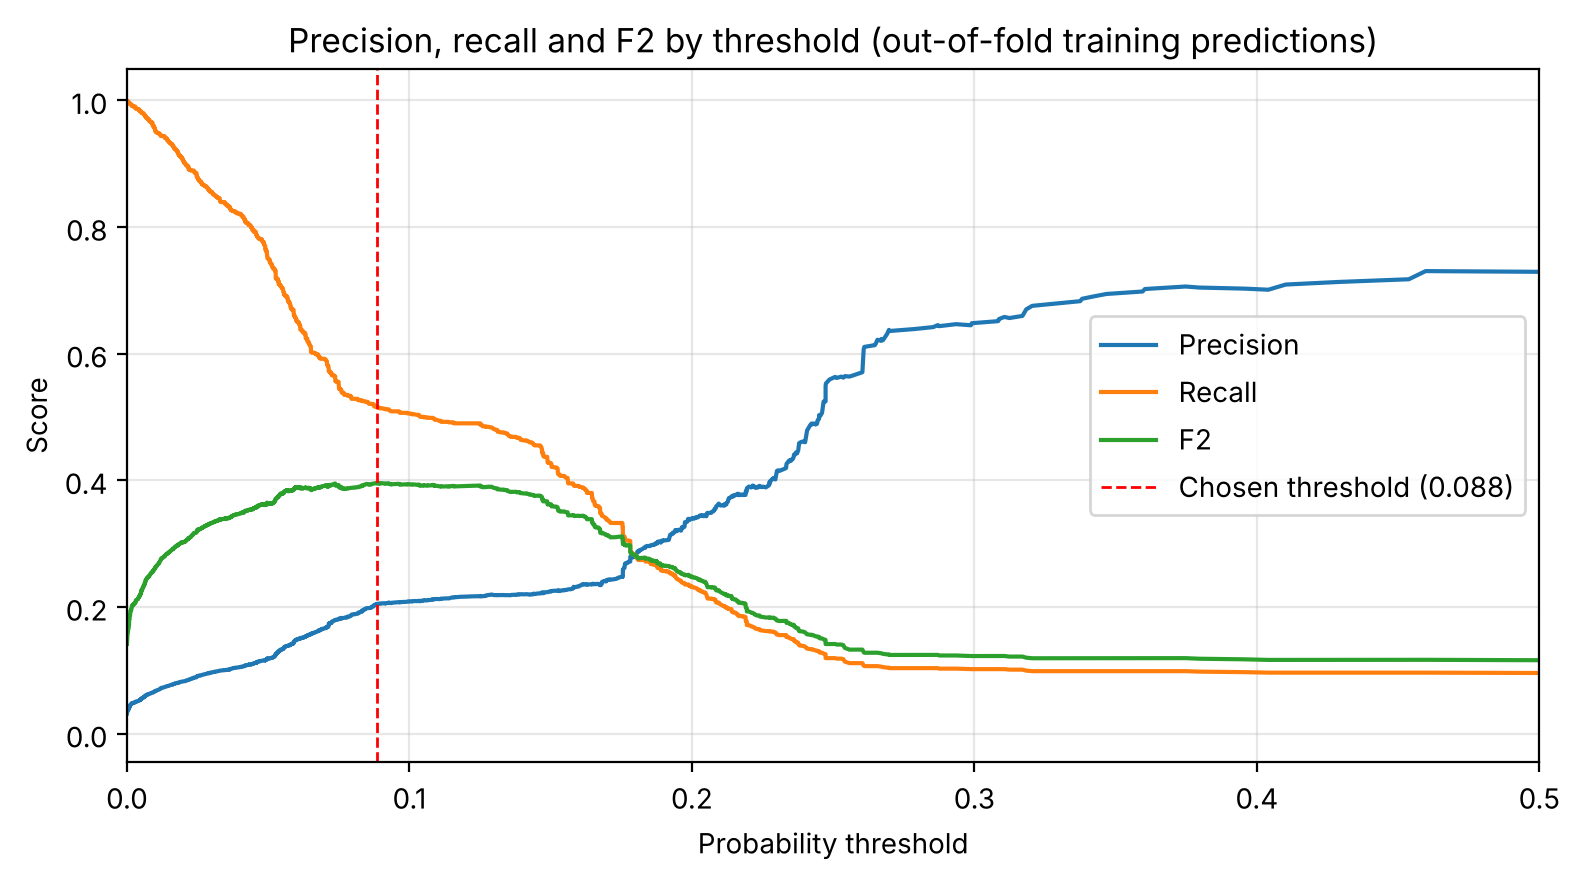

In [15]:
# Final model: tuned Logistic Regression + isotonic calibration, refitted on all training data
FINAL_NAME = "Tuned LR + isotonic"
final_model = CalibratedClassifierCV(clone(best_lr), method="isotonic", cv=5)
final_model.fit(X_train, y_train)

# Operating threshold chosen on out-of-fold training predictions only (the test set is not involved)
oof_final = oof[FINAL_NAME]
THRESHOLD, f2_at_thr, prec_at_thr, rec_at_thr = best_f2_threshold(y_train, oof_final)
print(f"F2-optimal threshold from out-of-fold predictions: {THRESHOLD:.3f}")
print(f"  at that threshold (OOF): precision {prec_at_thr:.3f}, recall {rec_at_thr:.3f}, F2 {f2_at_thr:.3f}")
print(f"  share of incidents with predicted probability >= 0.50: {(oof_final >= 0.5).mean():.2%}")
print(f"  highest predicted probability in the training OOF set: {oof_final.max():.2f}\n")

# Operating points a dispatcher could choose from
rows = []
for t in [0.03, 0.05, THRESHOLD, 0.15, 0.20, 0.30, 0.50]:
    flag = oof_final >= t
    tp = int((flag & (y_train == 1)).sum())
    rows.append({"Threshold": round(float(t), 3),
                 "Incidents flagged (%)": 100 * flag.mean(),
                 "Recall": tp / y_train.sum(),
                 "Precision": tp / max(flag.sum(), 1),
                 "False alarms per true hit": (flag.sum() - tp) / max(tp, 1),
                 "F2": fbeta_score(y_train, flag, beta=2)})
operating_df = pd.DataFrame(rows).set_index("Threshold")
display(operating_df.round(3))

prec, rec, thr = precision_recall_curve(y_train, oof_final)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(thr, prec[:-1], label="Precision")
ax.plot(thr, rec[:-1], label="Recall")
ax.plot(thr, 5 * prec[:-1] * rec[:-1] / (4 * prec[:-1] + rec[:-1] + 1e-12), label="F2")
ax.axvline(THRESHOLD, color="red", ls="--", lw=1, label=f"Chosen threshold ({THRESHOLD:.3f})")
ax.set_xlim(0, 0.5); ax.set_xlabel("Probability threshold"); ax.set_ylabel("Score")
ax.set_title("Precision, recall and F2 by threshold (out-of-fold training predictions)")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Reading the calibration and threshold results

Calibration fixes the probabilities and leaves the ranking almost unchanged. The raw model's mean prediction is 0.315 against an actual rate of 0.032, with a Brier score of 0.153. Isotonic calibration brings the mean to 0.032 and the Brier score to 0.0266, and the reliability curve follows the diagonal. Sigmoid scaling is close on the Brier score (0.0271) but its curve bends away from the diagonal between 0.03 and 0.20, the range where the operating threshold sits. We use isotonic.

PR-AUC drops slightly with isotonic calibration (0.269 to 0.265) because the step function gives many incidents the same probability, which creates ties in the ranking. We accept that loss in exchange for probabilities that mean what they say.

The model is modest even when calibrated. Always predicting the base rate gives a Brier score of 0.0310, so the calibrated model improves on that by about 14%.

The F2-optimal threshold is 0.088. At that point the model flags 8% of incidents, catches 52% of prolonged disruptions, and is right about 1 flag in 5 (about 3.9 false alarms per correct flag). F2 changes little between thresholds of 0.05 and 0.15 (0.36 to 0.40), so the exact value matters less than the region.

The thresholds proposed in Milestone 2 do not work with this model. That plan suggested acting at 50% during rush hour and 80% off-peak. Only 0.4% of incidents ever receive a probability of 0.50 or more, and at that threshold recall is under 10%. With onset information alone, most prolonged disruptions get a predicted probability between 5% and 30%. The table above gives the realistic choices: a dispatcher who wants to catch 75% of prolonged incidents has to act at a 5% probability and accept about 7 false alarms per hit.

The final model is the tuned Logistic Regression with isotonic calibration, with a default alert threshold of 0.088.

## Phase 6: Evaluation and analytical depth

Everything up to this point used the training set through cross-validation. The model, its hyperparameters, the calibration method and the threshold are now fixed, so the test set is used once.

### Metrics and why we chose them

- PR-AUC is the primary metric. With 3.2% positives, it measures how well prolonged incidents are ranked above short ones without being flattered by the large number of easy negatives.
- ROC-AUC is reported for comparison with other work, but it is optimistic under this imbalance.
- Recall and precision at the chosen threshold map to the two costs in the problem: a missed prolonged disruption strands passengers, and a false alarm pulls buses off surface routes. F2 combines them with recall weighted more heavily.
- The Brier score checks whether the probabilities can be trusted as probabilities.

### Baselines

Milestone 2 said the model must beat "predicting each incident from its cause code's historical norm". We build exactly that: a model that sees only `Code`, encoded as its historical prolonged rate. A no-skill baseline that always predicts the base rate is included as a floor.

In [16]:
# The sealed test set is opened here, once, after every modelling decision has been made.
X_test = test_df[FEATURES].copy()
X_test["Bound"] = X_test["Bound"].fillna("Unknown")
y_test = test_df[TARGET].values

p_train_resub = final_model.predict_proba(X_train)[:, 1]   # model scored on rows it was fitted on
p_test = final_model.predict_proba(X_test)[:, 1]

# Baseline from Milestone 2: each incident scored with its cause code's historical prolonged rate
code_baseline = Pipeline([
    ("encode", ColumnTransformer([("code", clone(target_encoder), ["Code"])])),
    ("model", LogisticRegression(max_iter=1000)),
])
p_code_oof = oof_proba(code_baseline)
p_code_test = code_baseline.fit(X_train, y_train).predict_proba(X_test)[:, 1]
THRESHOLD_CODE = best_f2_threshold(y_train, p_code_oof)[0]

def report(label, y, p, thr):
    flag = p >= thr
    return {"Evaluation": label,
            "PR-AUC": average_precision_score(y, p), "ROC-AUC": roc_auc_score(y, p),
            "Brier": brier_score_loss(y, p),
            "Precision": precision_score(y, flag, zero_division=0),
            "Recall": recall_score(y, flag), "F1": f1_score(y, flag),
            "F2": fbeta_score(y, flag, beta=2), "Flagged (%)": 100 * flag.mean()}

eval_df = pd.DataFrame([
    report("Final model: training (resubstitution)", y_train, p_train_resub, THRESHOLD),
    report("Final model: 5-fold CV (out-of-fold)", y_train, oof_final, THRESHOLD),
    report("Final model: TEST", y_test, p_test, THRESHOLD),
    report("Cause-code baseline: 5-fold CV", y_train, p_code_oof, THRESHOLD_CODE),
    report("Cause-code baseline: TEST", y_test, p_code_test, THRESHOLD_CODE),
    report("No-skill baseline (base rate): TEST", y_test, np.full(len(y_test), y_train.mean()), 0.5),
]).set_index("Evaluation")
display(eval_df.round(4))

fold_pr = per_fold(average_precision_score, y_train, oof_final)
print("Final model PR-AUC per CV fold:", np.round(fold_pr, 4),
      f"| mean {fold_pr.mean():.4f}, std {fold_pr.std():.4f}")

,PR-AUC,ROC-AUC,Brier,Precision,Recall,F1,F2,Flagged (%)
Evaluation,,,,,,,,
Final model: training (resubstitution),0.2952,0.8925,0.0261,0.2140,0.5312,0.3051,0.4098,7.9476
Final model: 5-fold CV (out-of-fold),0.2652,0.8778,0.0266,0.2049,0.5162,0.2934,0.3959,8.0665
Final model: TEST,0.2446,0.8652,0.0270,0.2060,0.5016,0.2921,0.3897,7.7647
Cause-code baseline: 5-fold CV,0.2293,0.8383,0.0278,0.2128,0.4719,0.2933,0.3795,7.1022
Cause-code baseline: TEST,0.2137,0.8181,0.0279,0.2092,0.4603,0.2877,0.3712,7.0156
No-skill baseline (base rate): TEST,0.0319,0.5000,0.0309,0.0000,0.0000,0.0000,0.0000,0.0000


Final model PR-AUC per CV fold: [0.2713 0.2664 0.2663 0.2801 0.2515] | mean 0.2671, std 0.0093


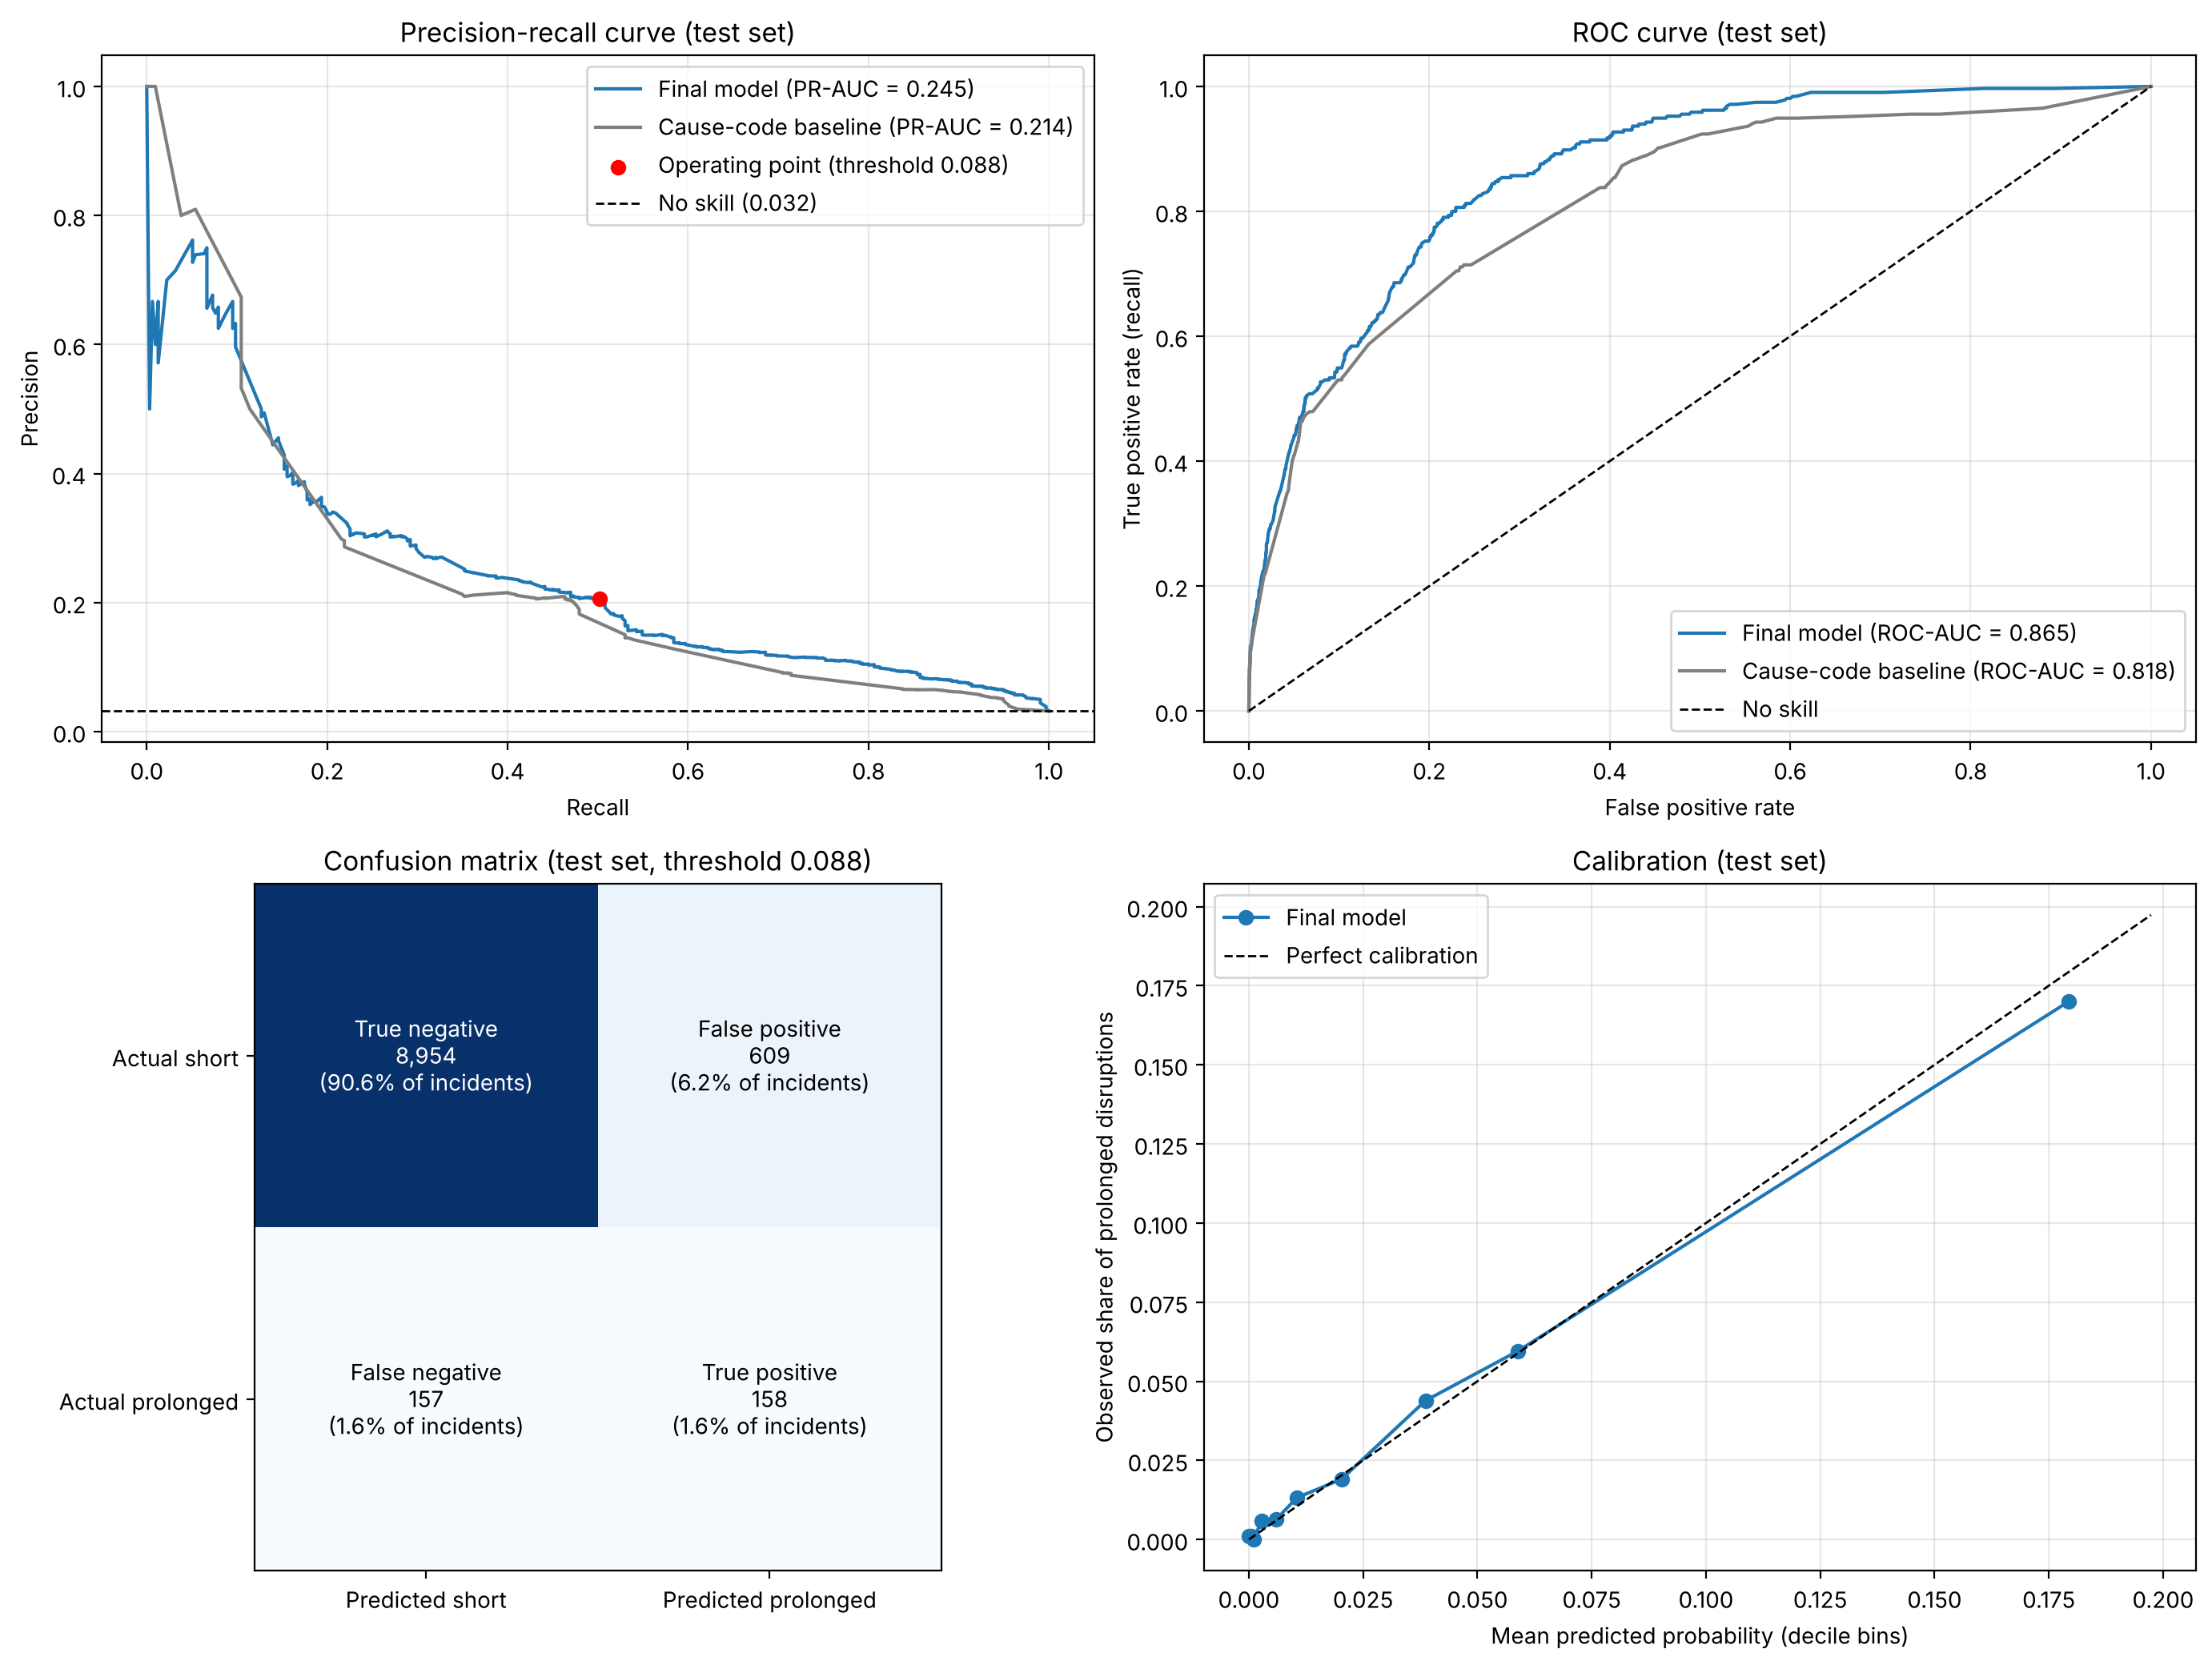

Test set: 158 prolonged disruptions caught, 157 missed, 609 false alarms, 8954 correctly left alone.
False alarms per caught disruption: 3.9


In [17]:
from sklearn.metrics import roc_curve

fig, axes = plt.subplots(2, 2, figsize=(14, 10.5))

# Precision-recall curve
ax = axes[0, 0]
for label, p, colour in [("Final model", p_test, "#1f77b4"), ("Cause-code baseline", p_code_test, "#7f7f7f")]:
    prec, rec, _ = precision_recall_curve(y_test, p)
    ax.plot(rec, prec, color=colour, label=f"{label} (PR-AUC = {average_precision_score(y_test, p):.3f})")
flag_test = p_test >= THRESHOLD
ax.scatter(recall_score(y_test, flag_test), precision_score(y_test, flag_test), color="red", zorder=5,
           label=f"Operating point (threshold {THRESHOLD:.3f})")
ax.axhline(y_test.mean(), color="k", ls="--", lw=1, label=f"No skill ({y_test.mean():.3f})")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_title("Precision-recall curve (test set)")
ax.legend(); ax.grid(alpha=0.3)

# ROC curve
ax = axes[0, 1]
for label, p, colour in [("Final model", p_test, "#1f77b4"), ("Cause-code baseline", p_code_test, "#7f7f7f")]:
    fpr, tpr, _ = roc_curve(y_test, p)
    ax.plot(fpr, tpr, color=colour, label=f"{label} (ROC-AUC = {roc_auc_score(y_test, p):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="No skill")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate (recall)")
ax.set_title("ROC curve (test set)"); ax.legend(); ax.grid(alpha=0.3)

# Confusion matrix
ax = axes[1, 0]
cm = confusion_matrix(y_test, flag_test)
ax.imshow(cm, cmap="Blues")
cell_names = [["True negative", "False positive"], ["False negative", "True positive"]]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cell_names[i][j]}\n{cm[i, j]:,}\n({cm[i, j] / cm.sum():.1%} of incidents)",
                ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks([0, 1]); ax.set_xticklabels(["Predicted short", "Predicted prolonged"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["Actual short", "Actual prolonged"])
ax.set_title(f"Confusion matrix (test set, threshold {THRESHOLD:.3f})")

# Calibration on the test set
ax = axes[1, 1]
frac_pos, mean_pred = calibration_curve(y_test, p_test, n_bins=10, strategy="quantile")
ax.plot(mean_pred, frac_pos, marker="o", label="Final model")
lim = max(mean_pred.max(), frac_pos.max()) * 1.1
ax.plot([0, lim], [0, lim], "k--", lw=1, label="Perfect calibration")
ax.set_xlabel("Mean predicted probability (decile bins)")
ax.set_ylabel("Observed share of prolonged disruptions")
ax.set_title("Calibration (test set)"); ax.legend(); ax.grid(alpha=0.3)

plt.tight_layout(); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Test set: {tp} prolonged disruptions caught, {fn} missed, {fp} false alarms, {tn} correctly left alone.")
print(f"False alarms per caught disruption: {fp / tp:.1f}")

In [18]:
# Bootstrap the test set to see how much the test metrics move with sampling noise
rng = np.random.default_rng(RANDOM_STATE)
boot = []
for _ in range(1000):
    idx = rng.integers(0, len(y_test), len(y_test))
    yb, pb, cb = y_test[idx], p_test[idx], p_code_test[idx]
    flag = pb >= THRESHOLD
    boot.append({"PR-AUC": average_precision_score(yb, pb),
                 "ROC-AUC": roc_auc_score(yb, pb),
                 "Recall": recall_score(yb, flag),
                 "Precision": precision_score(yb, flag, zero_division=0),
                 "PR-AUC gain over cause-code baseline": average_precision_score(yb, pb) - average_precision_score(yb, cb)})
boot = pd.DataFrame(boot)
ci_df = pd.DataFrame({"Test estimate": [average_precision_score(y_test, p_test), roc_auc_score(y_test, p_test),
                                        recall_score(y_test, p_test >= THRESHOLD),
                                        precision_score(y_test, p_test >= THRESHOLD),
                                        average_precision_score(y_test, p_test) - average_precision_score(y_test, p_code_test)],
                      "95% CI low": boot.quantile(0.025).values,
                      "95% CI high": boot.quantile(0.975).values}, index=boot.columns)
display(ci_df.round(4))

,Test estimate,95% CI low,95% CI high
PR-AUC,0.2446,0.2011,0.3011
ROC-AUC,0.8652,0.8466,0.8822
Recall,0.5016,0.4494,0.5585
Precision,0.2060,0.1798,0.2363
PR-AUC gain over cause-code baseline,0.0309,0.0141,0.0508


### Test results

On the test set the final model reaches a PR-AUC of 0.245 and a ROC-AUC of 0.865, with a Brier score of 0.027. At the 0.088 threshold it catches 158 of 315 prolonged disruptions (recall 0.50) and raises 609 false alarms (precision 0.21), flagging 7.8% of incidents.

A PR-AUC of 0.245 is about 7.7 times the no-skill value of 0.032, so the model ranks incidents far better than chance. In absolute terms it is still weak: at the operating point, four of every five alerts are wrong and half of the prolonged disruptions are missed.

The model beats the cause-code baseline by a small margin. The baseline scores 0.214 on the test set, so the other five features add 0.031 PR-AUC. The bootstrap interval for that gain is 0.014 to 0.051, which excludes zero, so the gain is real. At their respective thresholds the model catches 50% of prolonged incidents against the baseline's 46%, with the same precision. The Milestone 2 success criterion is met, though most of the predictive power is already in the incident code.

The confusion matrix in operational terms: of 9,878 test incidents, the model would have triggered a shuttle decision on 767. Of those, 158 were prolonged disruptions and 609 cleared within 15 minutes. It stayed silent on 157 incidents that went on to exceed 15 minutes.

The test estimate carries real uncertainty. With 315 positives, the 95% bootstrap interval for PR-AUC is 0.20 to 0.30, and for recall it is 0.45 to 0.56. The cross-validation value (0.265) is inside the PR-AUC interval, so the lower test number is consistent with sampling noise.

Calibration holds on unseen data. The test Brier score (0.0270) is almost equal to the cross-validated one (0.0266), and the test calibration curve stays close to the diagonal, with a slight overestimate in the top decile (predicted 0.18, observed 0.17).

### Training, validation and test performance: bias or variance?

| | PR-AUC | ROC-AUC | Recall | Precision | Brier |
|---|---|---|---|---|---|
| Training (model scored on its own training rows) | 0.295 | 0.893 | 0.53 | 0.21 | 0.0261 |
| 5-fold cross-validation | 0.265 | 0.878 | 0.52 | 0.20 | 0.0266 |
| Test | 0.245 | 0.865 | 0.50 | 0.21 | 0.0270 |

The gaps are small. PR-AUC falls by 0.03 from training to validation and by another 0.02 to test, and recall and precision at the threshold are nearly identical across the three. A high-variance model would show a much larger drop.

The learning curve below shows what happens to both scores as the training set grows.

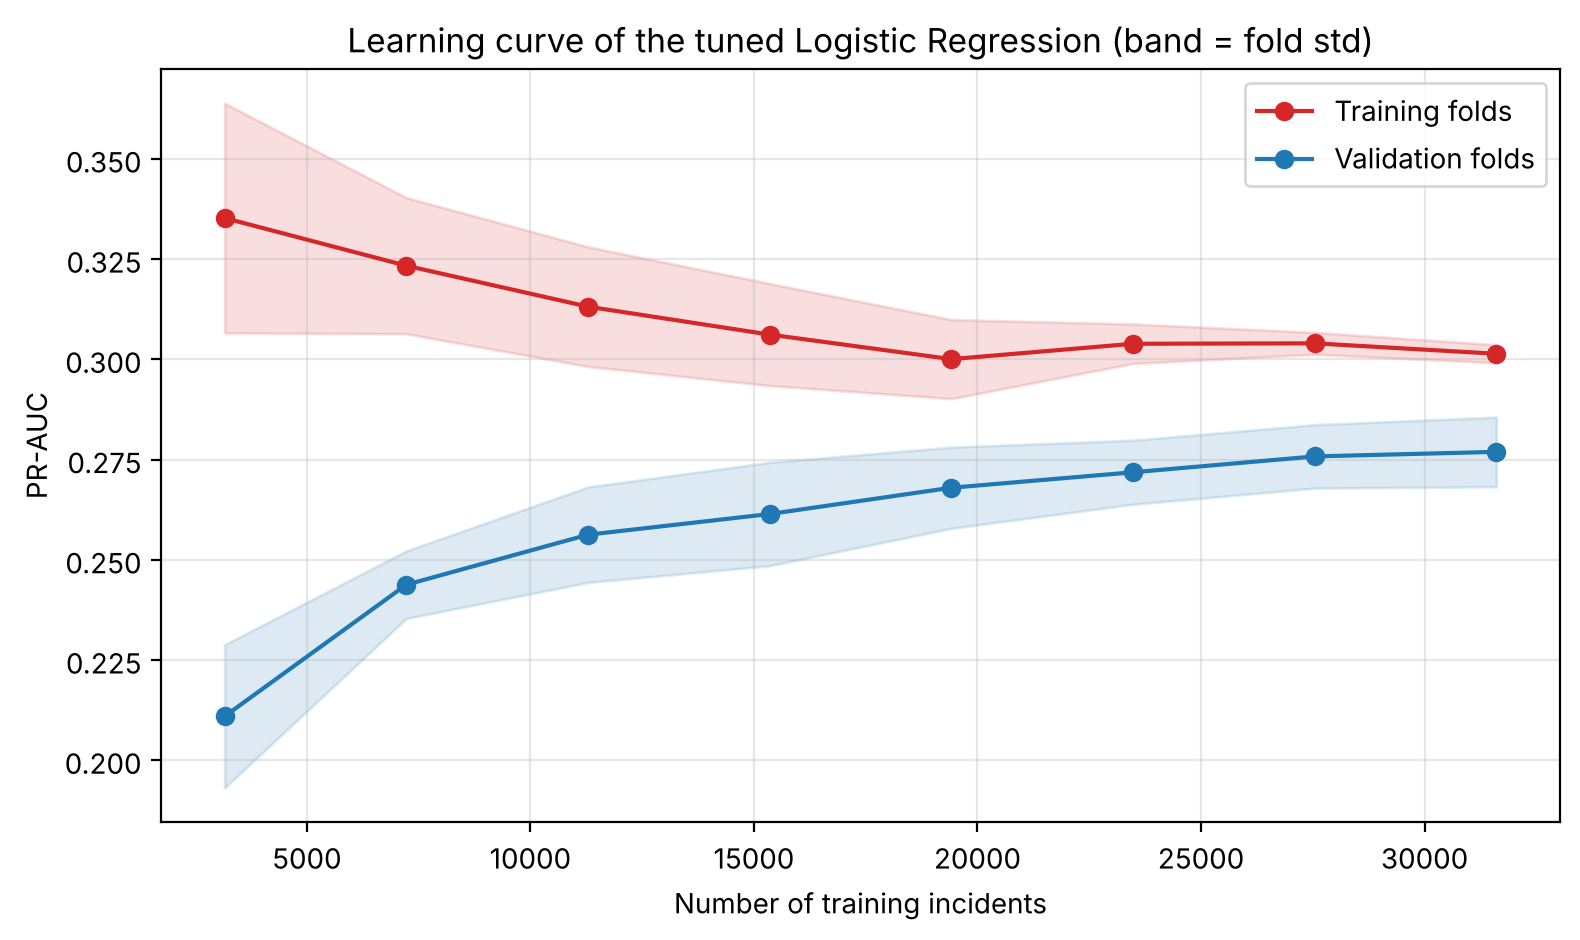

,Training rows,Train PR-AUC,Validation PR-AUC,Gap
0,3160,0.3353,0.2110,0.1243
1,7224,0.3234,0.2438,0.0796
2,11288,0.3131,0.2563,0.0569
3,15351,0.3062,0.2614,0.0448
4,19415,0.3001,0.2680,0.0321
5,23479,0.3039,0.2718,0.0321
6,27543,0.3040,0.2758,0.0282
7,31607,0.3014,0.2769,0.0245


In [19]:
from sklearn.model_selection import learning_curve

sizes, train_scores, val_scores = learning_curve(
    clone(best_lr), X_train, y_train, cv=cv, scoring="average_precision",
    train_sizes=np.linspace(0.1, 1.0, 8), n_jobs=-1, shuffle=True, random_state=RANDOM_STATE)

fig, ax = plt.subplots(figsize=(8, 4.8))
for scores, label, colour in [(train_scores, "Training folds", "#d62728"), (val_scores, "Validation folds", "#1f77b4")]:
    mean, std = scores.mean(axis=1), scores.std(axis=1)
    ax.plot(sizes, mean, marker="o", color=colour, label=label)
    ax.fill_between(sizes, mean - std, mean + std, color=colour, alpha=0.15)
ax.set_xlabel("Number of training incidents"); ax.set_ylabel("PR-AUC")
ax.set_title("Learning curve of the tuned Logistic Regression (band = fold std)")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

display(pd.DataFrame({"Training rows": sizes, "Train PR-AUC": train_scores.mean(axis=1),
                      "Validation PR-AUC": val_scores.mean(axis=1),
                      "Gap": train_scores.mean(axis=1) - val_scores.mean(axis=1)}).round(4))

The learning curve points to bias as the main limitation. As training data grows from 3,000 to 32,000 incidents, the training score falls from 0.335 to 0.301 and the validation score rises from 0.211 to 0.277. The gap between them shrinks from 0.12 to 0.025. Validation performance is nearly flat over the last three steps (0.272, 0.276, 0.277), so collecting more incidents of the same kind would add very little.

Both curves are converging on a low value of roughly 0.28 to 0.30. Even on data it has already seen, the model cannot do better than about 0.30. That is the signature of high bias, or more precisely of a ceiling set by the inputs: the tuned tree models hit the same ceiling in Phase 5, so a more flexible model does not remove it. Better performance has to come from new information about the incident.

### Robustness and sensitivity

One cross-validation run and one test set could be lucky or unlucky. We run four further checks, all on the training set:

1. Repeated cross-validation with five different shuffles, to see how much the estimate depends on the fold assignment.
2. A split by time: fit on 2023, validate on 2024. Random folds mix both years, and incidents from the same day or the same underlying event can land on both sides of a split. In deployment the model always predicts the future.
3. Feature ablation: refit with one feature removed at a time.
4. Target sensitivity: move the 15-minute definition of "prolonged" to 5, 10, 20 and 30 minutes.

In [20]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

# 1) Does the CV estimate depend on how the folds were drawn? 5-fold CV repeated with 5 different shuffles.
rkf = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)
rep_scores = cross_val_score(clone(best_lr), X_train, y_train, cv=rkf, scoring="average_precision", n_jobs=-1)
print(f"Repeated 5x5 CV PR-AUC: mean {rep_scores.mean():.4f}, std {rep_scores.std():.4f}, "
      f"min {rep_scores.min():.4f}, max {rep_scores.max():.4f}")

# 2) Does the model hold up forward in time? Fit on 2023 training rows, score 2024 training rows.
year = train_df["Date"].dt.year.values
is_2023, is_2024 = year == 2023, year == 2024
temporal_model = CalibratedClassifierCV(clone(best_lr), method="isotonic", cv=5).fit(X_train[is_2023], y_train[is_2023])
p_2024 = temporal_model.predict_proba(X_train[is_2024])[:, 1]
flag_2024 = p_2024 >= THRESHOLD
temporal_df = pd.DataFrame({
    "PR-AUC": [average_precision_score(y_train, oof_final), average_precision_score(y_train[is_2024], p_2024)],
    "ROC-AUC": [roc_auc_score(y_train, oof_final), roc_auc_score(y_train[is_2024], p_2024)],
    "Brier": [brier_score_loss(y_train, oof_final), brier_score_loss(y_train[is_2024], p_2024)],
    "Recall @ threshold": [recall_score(y_train, oof_final >= THRESHOLD), recall_score(y_train[is_2024], flag_2024)],
    "Precision @ threshold": [precision_score(y_train, oof_final >= THRESHOLD), precision_score(y_train[is_2024], flag_2024)],
    "Actual positive rate": [y_train.mean(), y_train[is_2024].mean()],
    "Mean predicted prob.": [oof_final.mean(), p_2024.mean()],
}, index=["Random 5-fold CV (2023 + 2024 mixed)", "Train on 2023, validate on 2024"])
display(temporal_df.round(4))

Repeated 5x5 CV PR-AUC: mean 0.2726, std 0.0233, min 0.2310, max 0.3291


,PR-AUC,ROC-AUC,Brier,Recall @ threshold,Precision @ threshold,Actual positive rate,Mean predicted prob.
Random 5-fold CV (2023 + 2024 mixed),0.2652,0.8778,0.0266,0.5162,0.2049,0.0320,0.032
"Train on 2023, validate on 2024",0.2324,0.8647,0.0261,0.4830,0.1949,0.0306,0.030


In [21]:
# 3) Which inputs does the model depend on? Refit with one feature removed at a time.
def lr_without(dropped):
    """Tuned LR pipeline rebuilt without the listed features."""
    low = [c for c in low_card_cats if c not in dropped]
    high = [c for c in high_card_cats if c not in dropped]
    num = [c for c in numeric_features if c not in dropped]
    smooth = best_lr.named_steps["preprocessor"].named_transformers_["high_card"].smooth
    parts = []
    if low:
        parts.append(("low_card", Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
                                            ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), low))
    if high:
        parts.append(("high_card", clone(target_encoder).set_params(smooth=smooth), high))
    if num:
        parts.append(("num", StandardScaler(), num))
    return Pipeline([("preprocessor", ColumnTransformer(parts)), ("model", clone(best_lr.named_steps["model"]))])

full_pr = per_fold(average_precision_score, y_train, oof["Tuned LR, raw output"])
rows = [{"Feature set": "All six features", "PR-AUC": full_pr.mean(), "Fold std": full_pr.std(),
         "ROC-AUC": roc_auc_score(y_train, oof["Tuned LR, raw output"])}]
for dropped in [["Code"], ["Station_Clean"], ["Bound"], ["Line_Clean"], ["Hour", "Is_Rush_Hour"]]:
    p = oof_proba(lr_without(dropped))
    folds = per_fold(average_precision_score, y_train, p)
    rows.append({"Feature set": "Without " + " and ".join(dropped), "PR-AUC": folds.mean(),
                 "Fold std": folds.std(), "ROC-AUC": roc_auc_score(y_train, p)})
ablation_df = pd.DataFrame(rows).set_index("Feature set")
ablation_df["PR-AUC change"] = ablation_df["PR-AUC"] - ablation_df["PR-AUC"].iloc[0]
display(ablation_df.round(4))

# 4) Does the conclusion depend on the 15-minute cut-off? Same pipeline, different target definitions.
rows = []
for minutes in [5, 10, 15, 20, 30]:
    y_alt = (train_df["Min Delay"] > minutes).astype(int).values
    p = oof_proba(clone(best_lr), y=y_alt)
    rows.append({"Target: delay longer than (min)": minutes, "Positive rate": y_alt.mean(),
                 "PR-AUC": average_precision_score(y_alt, p),
                 "Lift over no skill (PR-AUC / positive rate)": average_precision_score(y_alt, p) / y_alt.mean(),
                 "ROC-AUC": roc_auc_score(y_alt, p)})
display(pd.DataFrame(rows).set_index("Target: delay longer than (min)").round(4))

,PR-AUC,Fold std,ROC-AUC,PR-AUC change
Feature set,,,,
All six features,0.2775,0.0093,0.8782,0.0000
Without Code,0.0727,0.0067,0.7313,-0.2048
Without Station_Clean,0.2745,0.0081,0.8779,-0.0029
Without Bound,0.2613,0.0092,0.8474,-0.0161
Without Line_Clean,0.2781,0.0098,0.8773,0.0006
Without Hour and Is_Rush_Hour,0.2738,0.0101,0.8804,-0.0037


,Positive rate,PR-AUC,Lift over no skill (PR-AUC / positive rate),ROC-AUC
Target: delay longer than (min),,,,
5,0.1515,0.4905,3.2373,0.8444
10,0.0588,0.3386,5.7538,0.8634
15,0.0320,0.2687,8.3915,0.8782
20,0.0194,0.2428,12.5390,0.8780
30,0.0087,0.2118,24.3272,0.8784


### What the robustness checks show

Fold assignment matters more than the single CV run suggested. Across 25 folds the PR-AUC averages 0.273 with a standard deviation of 0.023, ranging from 0.23 to 0.33. Each validation fold has only 253 positives, so PR-AUC is a noisy measure at this sample size. Differences of 0.01 between models or settings should not be over-read, which supports treating the three tuned models as tied.

Performance drops when the model has to predict forward in time. Trained on 2023 and validated on 2024, PR-AUC is 0.232 against 0.265 from random folds, and recall at the threshold falls from 0.52 to 0.48. Random cross-validation is therefore optimistic by about 0.03, and the forward-looking figure is the better guide to what deployment would deliver. The test set is also a random split, so the test PR-AUC of 0.245 carries some of the same optimism. Calibration held up across years: the mean prediction for 2024 was 0.030 against an actual rate of 0.031.

The model depends almost entirely on the incident code. Removing `Code` cuts PR-AUC from 0.278 to 0.073. Removing `Station_Clean`, `Line_Clean` or the two time features changes it by less than 0.004 each, which is inside the noise. `Bound` is the only other feature with a visible contribution (0.016 PR-AUC, and ROC-AUC falls from 0.878 to 0.847).

The findings do not depend on the 15-minute cut-off. ROC-AUC stays between 0.84 and 0.88 for every threshold from 5 to 30 minutes. PR-AUC falls as the target gets rarer (0.49 at 5 minutes, 0.21 at 30 minutes), which is expected because PR-AUC scales with the base rate. The lift over no skill rises from 3 times to 24 times.

### Error analysis

Milestone 2 required that errors "not fall disproportionately on particular lines or times of day". We check that first, and then look at which incidents the model gets wrong and what the model relies on.


By Line_Clean


,Incidents,Prolonged,Actual rate,Mean predicted prob.,PR-AUC,Recall,Precision,Flagged (%)
Line_Clean,,,,,,,,
BD,16335,493,0.030,0.029,0.270,0.501,0.218,6.948
Multiple lines,574,0,0.000,0.000,NaN,NaN,NaN,0.000
SHP,1295,64,0.049,0.060,0.293,0.688,0.185,18.378
SRT,584,45,0.077,0.088,0.194,0.956,0.155,47.432
YU,20641,661,0.032,0.032,0.265,0.481,0.208,7.417



By Time of day


,Incidents,Prolonged,Actual rate,Mean predicted prob.,PR-AUC,Recall,Precision,Flagged (%)
Time of day,,,,,,,,
Night (0-5h),5645,165,0.029,0.027,0.186,0.521,0.170,8.946
AM peak (6-9h),6884,160,0.023,0.024,0.255,0.581,0.185,7.321
Midday (10-14h),8422,299,0.036,0.037,0.309,0.532,0.228,8.276
PM peak (15-19h),10492,369,0.035,0.030,0.271,0.499,0.230,7.625
Evening (20-23h),8066,272,0.034,0.039,0.271,0.482,0.192,8.443



By Is_Rush_Hour


,Incidents,Prolonged,Actual rate,Mean predicted prob.,PR-AUC,Recall,Precision,Flagged (%)
Is_Rush_Hour,,,,,,,,
0,26096,889,0.034,0.036,0.278,0.526,0.211,8.519
1,13413,376,0.028,0.025,0.233,0.492,0.192,7.187



By Bound recorded


,Incidents,Prolonged,Actual rate,Mean predicted prob.,PR-AUC,Recall,Precision,Flagged (%)
Bound recorded,,,,,,,,
Bound missing,14389,17,0.001,0.001,0.022,0.059,0.091,0.076
Bound recorded,25120,1248,0.050,0.050,0.269,0.522,0.205,12.643


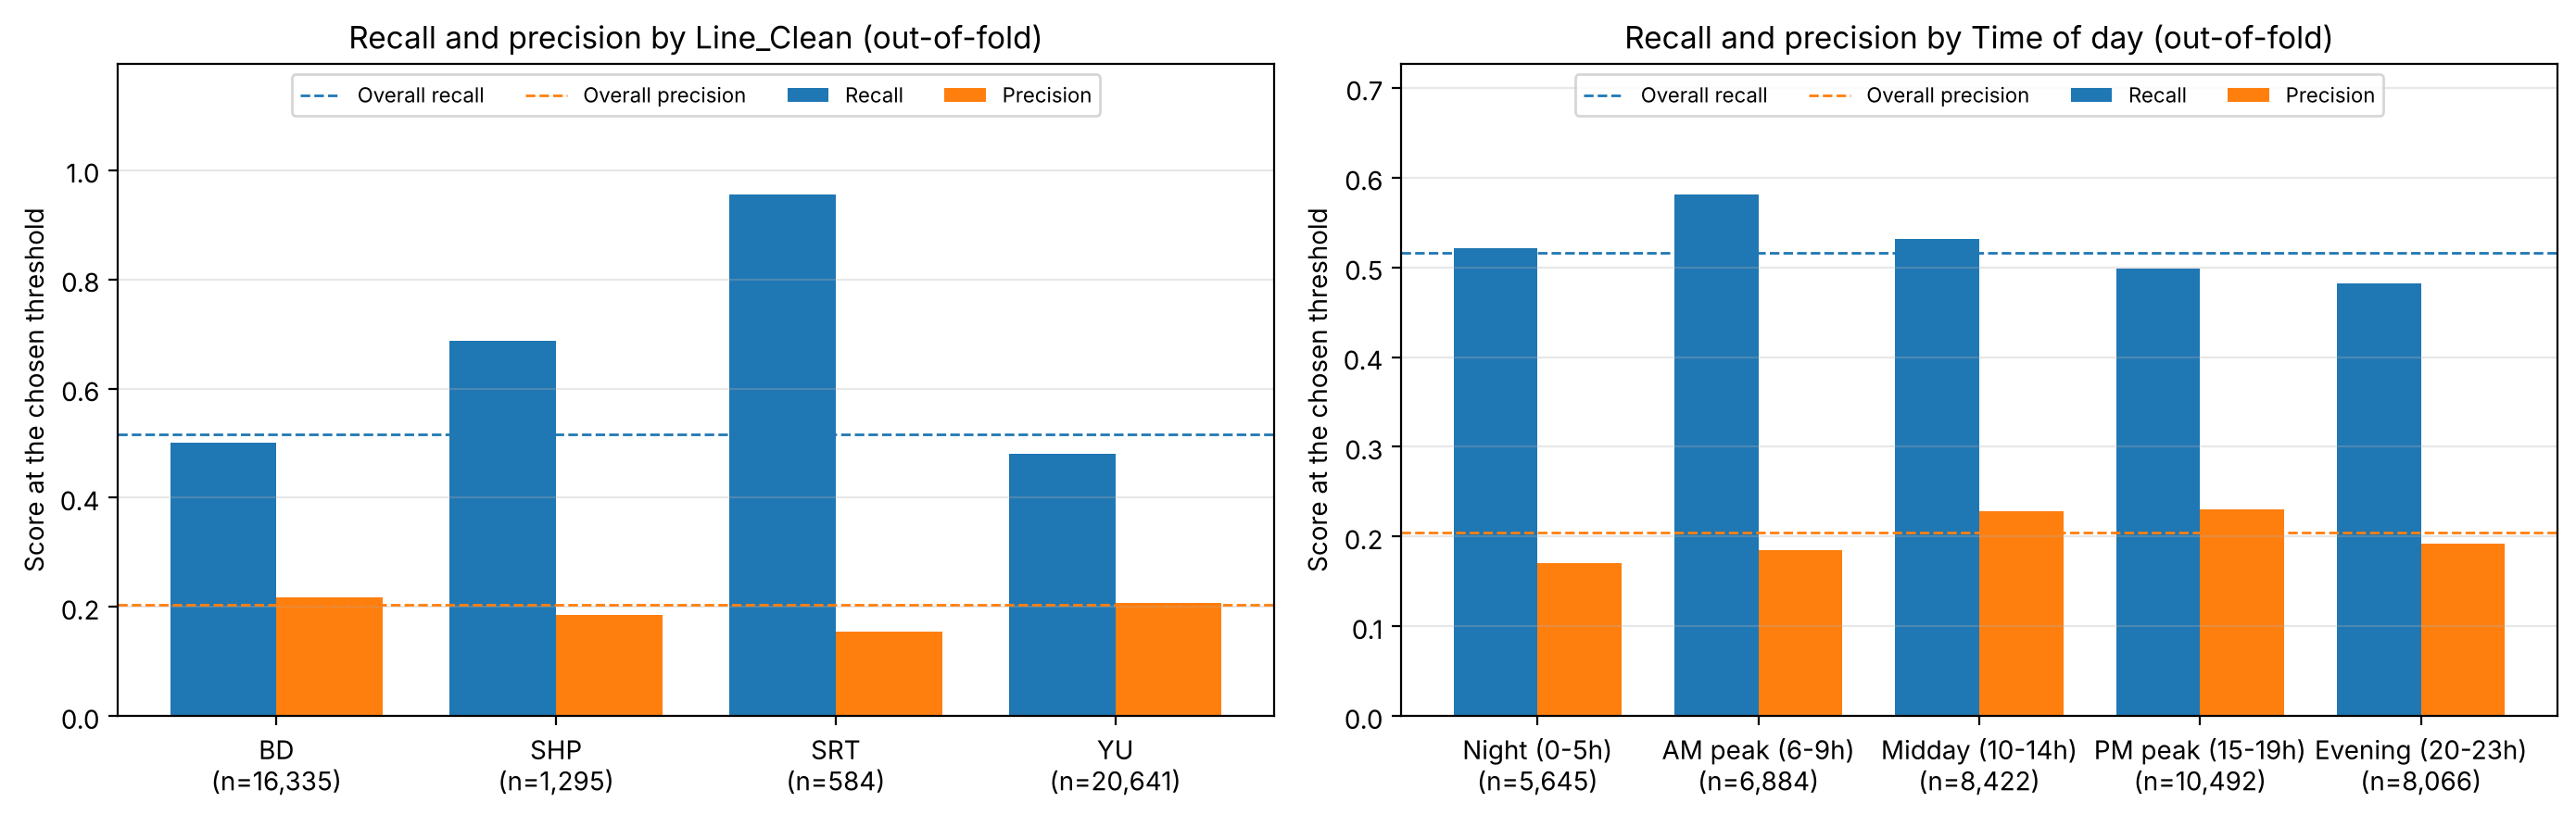

In [22]:
# Subgroup results use the out-of-fold training predictions: about 1,265 positives instead of about 315 in the test set
analysis = train_df.assign(p=oof_final, y=y_train, flagged=oof_final >= THRESHOLD)
analysis["Time of day"] = pd.cut(analysis["Hour"], [-1, 5, 9, 14, 19, 23],
                                 labels=["Night (0-5h)", "AM peak (6-9h)", "Midday (10-14h)",
                                         "PM peak (15-19h)", "Evening (20-23h)"])
analysis["Bound recorded"] = np.where(train_df["Bound"].isna(), "Bound missing", "Bound recorded")

def subgroup_table(column, min_rows=100):
    rows = []
    for value, g in analysis.groupby(column, observed=True):
        if len(g) < min_rows:
            continue
        pos = int(g["y"].sum())
        rows.append({column: value, "Incidents": len(g), "Prolonged": pos,
                     "Actual rate": g["y"].mean(), "Mean predicted prob.": g["p"].mean(),
                     "PR-AUC": average_precision_score(g["y"], g["p"]) if pos > 0 else np.nan,
                     "Recall": g.loc[g["y"] == 1, "flagged"].mean() if pos > 0 else np.nan,
                     "Precision": g.loc[g["flagged"], "y"].mean() if g["flagged"].any() else np.nan,
                     "Flagged (%)": 100 * g["flagged"].mean()})
    return pd.DataFrame(rows).set_index(column)

subgroup_tables = {col: subgroup_table(col) for col in ["Line_Clean", "Time of day", "Is_Rush_Hour", "Bound recorded"]}
for col, table in subgroup_tables.items():
    print(f"\nBy {col}")
    display(table.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, col in zip(axes, ["Line_Clean", "Time of day"]):
    t = subgroup_tables[col].dropna(subset=["Recall"])
    x = np.arange(len(t)); w = 0.38
    ax.bar(x - w/2, t["Recall"], w, label="Recall", color="#1f77b4")
    ax.bar(x + w/2, t["Precision"], w, label="Precision", color="#ff7f0e")
    ax.axhline(recall_score(y_train, oof_final >= THRESHOLD), color="#1f77b4", ls="--", lw=1, label="Overall recall")
    ax.axhline(precision_score(y_train, oof_final >= THRESHOLD), color="#ff7f0e", ls="--", lw=1, label="Overall precision")
    ax.set_xticks(x); ax.set_xticklabels([f"{i}\n(n={int(n):,})" for i, n in zip(t.index, t["Incidents"])])
    ax.set_ylabel("Score at the chosen threshold"); ax.set_title(f"Recall and precision by {col} (out-of-fold)")
    ax.set_ylim(0, 1.25 * t["Recall"].max()); ax.legend(fontsize=8, ncol=4, loc="upper center"); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

Out-of-fold errors at threshold 0.088: 653 caught, 612 missed, 2534 false alarms

Codes responsible for the most missed prolonged disruptions


,Description,Incidents,Prolonged,Actual_rate,Mean_predicted,Missed (FN),Share of all misses (%)
Code,,,,,,,
SUO,Passenger Other,3908,187,0.048,0.034,177,28.922
SUDP,Disorderly Patron,5502,156,0.028,0.024,154,25.163
MUIR,Injured or ill Customer (On Train) - Medical A...,1054,63,0.060,0.066,55,8.987
SUAP,Assault / Patron Involved,993,49,0.049,0.034,44,7.190
PUOPO,OPTO (COMMS) Train Door Monitoring,1989,22,0.011,0.017,22,3.595
MUO,Miscellaneous Other,1675,14,0.008,0.005,14,2.288
SUAE,Assault / Employee Involved,347,12,0.035,0.022,12,1.961
TUO,Transportation Department - Other,497,9,0.018,0.022,9,1.471



Codes responsible for the most false alarms


,Description,Incidents,Prolonged,Actual_rate,Mean_predicted,False alarms (FP),Share of all false alarms (%)
Code,,,,,,,
SUUT,Unauthorized at Track Level,1115,190,0.170,0.168,884,34.886
MUI,Injured or ill Customer (On Train) - Transported,635,127,0.200,0.202,488,19.258
SUEAS,Emergency Alarm Station Activation,209,34,0.163,0.165,170,6.709
PUTWZ,Work Zone Problems - Track,168,24,0.143,0.134,129,5.091
SUPOL,Held By Polce - Non-TTC Related,112,18,0.161,0.146,84,3.315
MUIR,Injured or ill Customer (On Train) - Medical A...,1054,63,0.060,0.066,54,2.131
ERTC,Train Control - VOBC,59,7,0.119,0.192,52,2.052
PUTDN,Debris At Track Level - Uncontrollable,61,11,0.180,0.164,50,1.973


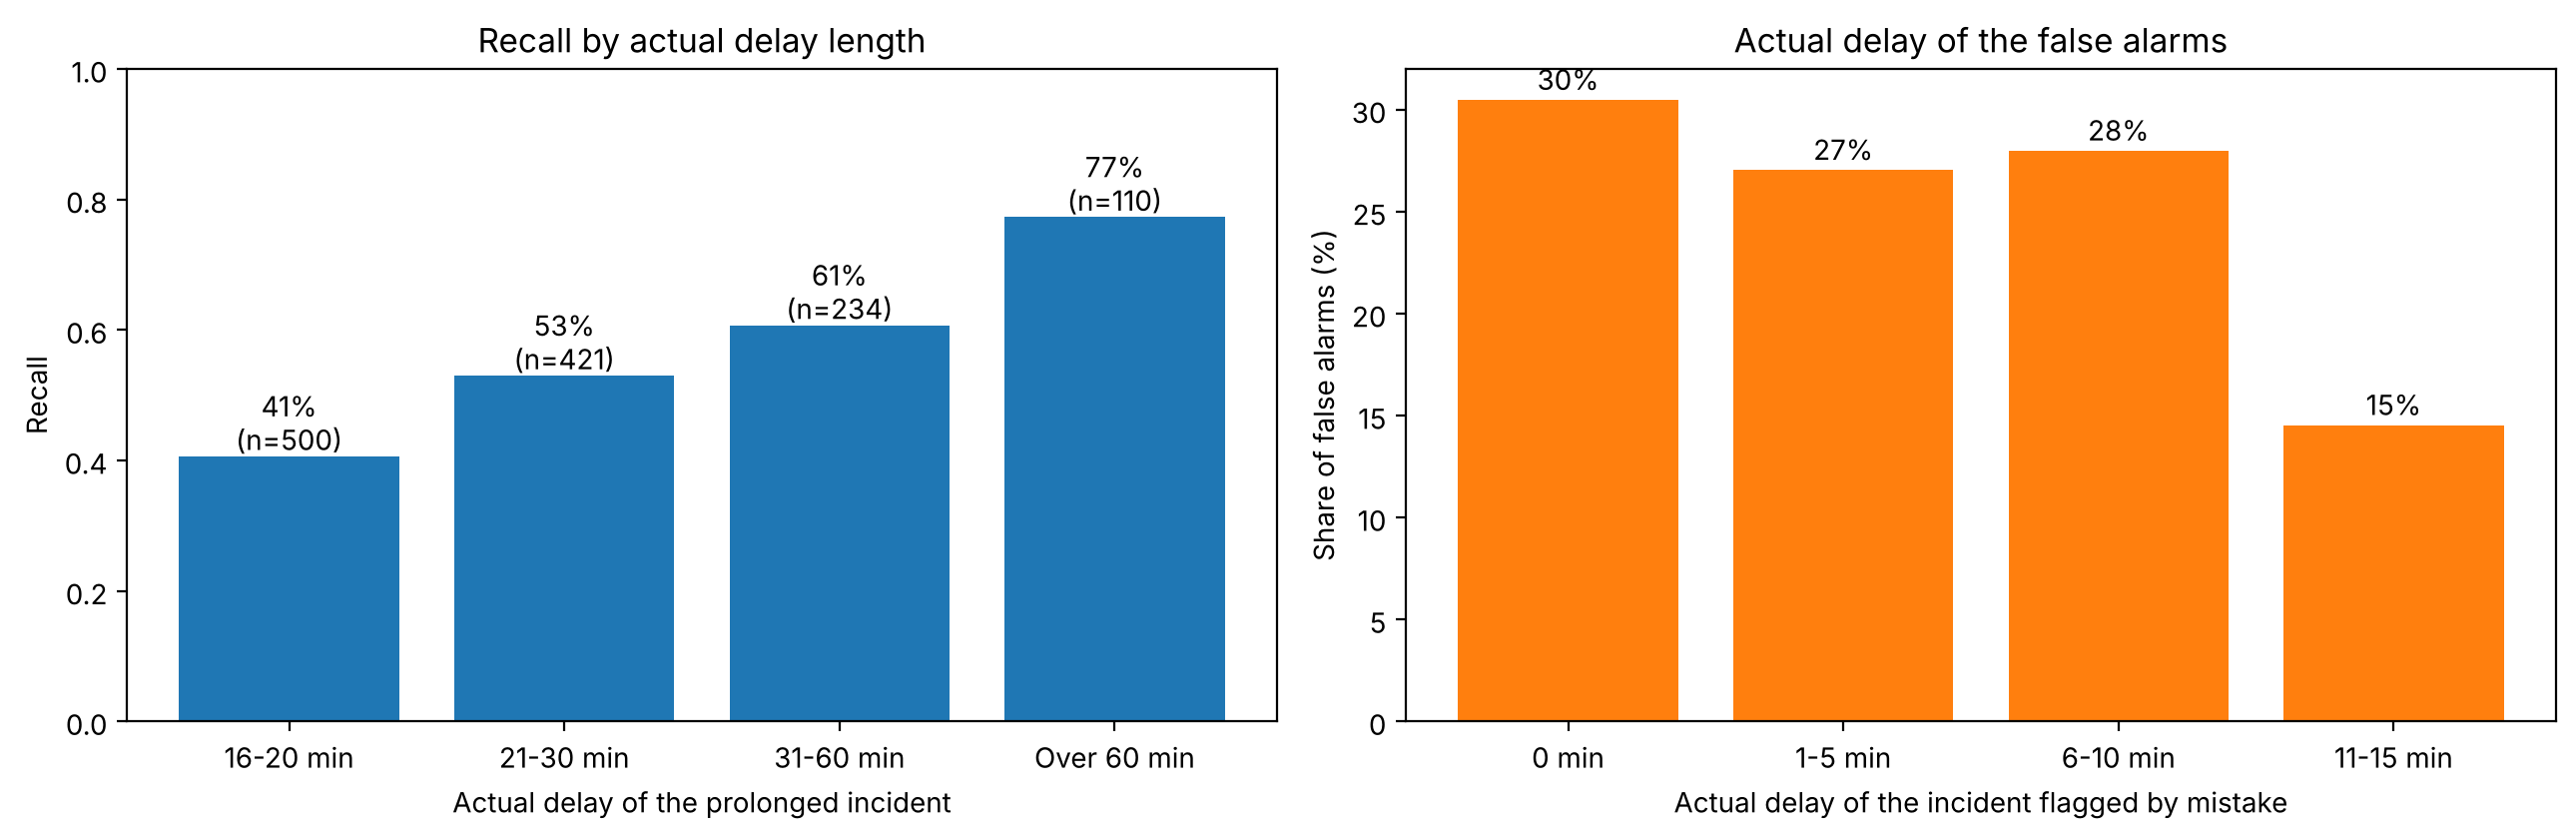

In [23]:
is_fn = (analysis["y"] == 1) & (~analysis["flagged"])
is_fp = (analysis["y"] == 0) & (analysis["flagged"])
is_tp = (analysis["y"] == 1) & (analysis["flagged"])
print(f"Out-of-fold errors at threshold {THRESHOLD:.3f}: {is_tp.sum()} caught, {is_fn.sum()} missed, {is_fp.sum()} false alarms")

# Errors by incident code
by_code = analysis.groupby("Code").agg(
    Description=("Code_Description", "first"), Incidents=("y", "size"), Prolonged=("y", "sum"),
    Actual_rate=("y", "mean"), Mean_predicted=("p", "mean"))
by_code["Missed (FN)"] = analysis[is_fn].groupby("Code").size()
by_code["False alarms (FP)"] = analysis[is_fp].groupby("Code").size()
by_code = by_code.fillna(0).astype({"Missed (FN)": int, "False alarms (FP)": int})
by_code["Share of all misses (%)"] = 100 * by_code["Missed (FN)"] / is_fn.sum()
by_code["Share of all false alarms (%)"] = 100 * by_code["False alarms (FP)"] / is_fp.sum()

print("\nCodes responsible for the most missed prolonged disruptions")
display(by_code.sort_values("Missed (FN)", ascending=False).head(8)
        [["Description", "Incidents", "Prolonged", "Actual_rate", "Mean_predicted", "Missed (FN)", "Share of all misses (%)"]].round(3))
print("\nCodes responsible for the most false alarms")
display(by_code.sort_values("False alarms (FP)", ascending=False).head(8)
        [["Description", "Incidents", "Prolonged", "Actual_rate", "Mean_predicted", "False alarms (FP)", "Share of all false alarms (%)"]].round(3))

# Does the model miss the long incidents or the borderline ones?
positives = analysis[analysis["y"] == 1]
bands = pd.cut(positives["Min Delay"], [15, 20, 30, 60, 10_000],
               labels=["16-20 min", "21-30 min", "31-60 min", "Over 60 min"])
recall_by_band = positives.groupby(bands, observed=True)["flagged"].agg(Prolonged="size", Recall="mean")

false_alarms = analysis[is_fp]
fa_bands = pd.cut(false_alarms["Min Delay"], [-1, 0, 5, 10, 15],
                  labels=["0 min", "1-5 min", "6-10 min", "11-15 min"])
fa_share = (fa_bands.value_counts(normalize=True).sort_index() * 100)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
axes[0].bar(recall_by_band.index.astype(str), recall_by_band["Recall"], color="#1f77b4")
for i, (n, r) in enumerate(zip(recall_by_band["Prolonged"], recall_by_band["Recall"])):
    axes[0].text(i, r + 0.01, f"{r:.0%}\n(n={n})", ha="center")
axes[0].set_ylim(0, 1); axes[0].set_xlabel("Actual delay of the prolonged incident"); axes[0].set_ylabel("Recall")
axes[0].set_title("Recall by actual delay length")
axes[1].bar(fa_share.index.astype(str), fa_share.values, color="#ff7f0e")
for i, v in enumerate(fa_share.values):
    axes[1].text(i, v + 0.5, f"{v:.0f}%", ha="center")
axes[1].set_xlabel("Actual delay of the incident flagged by mistake"); axes[1].set_ylabel("Share of false alarms (%)")
axes[1].set_title("Actual delay of the false alarms")
plt.tight_layout(); plt.show()

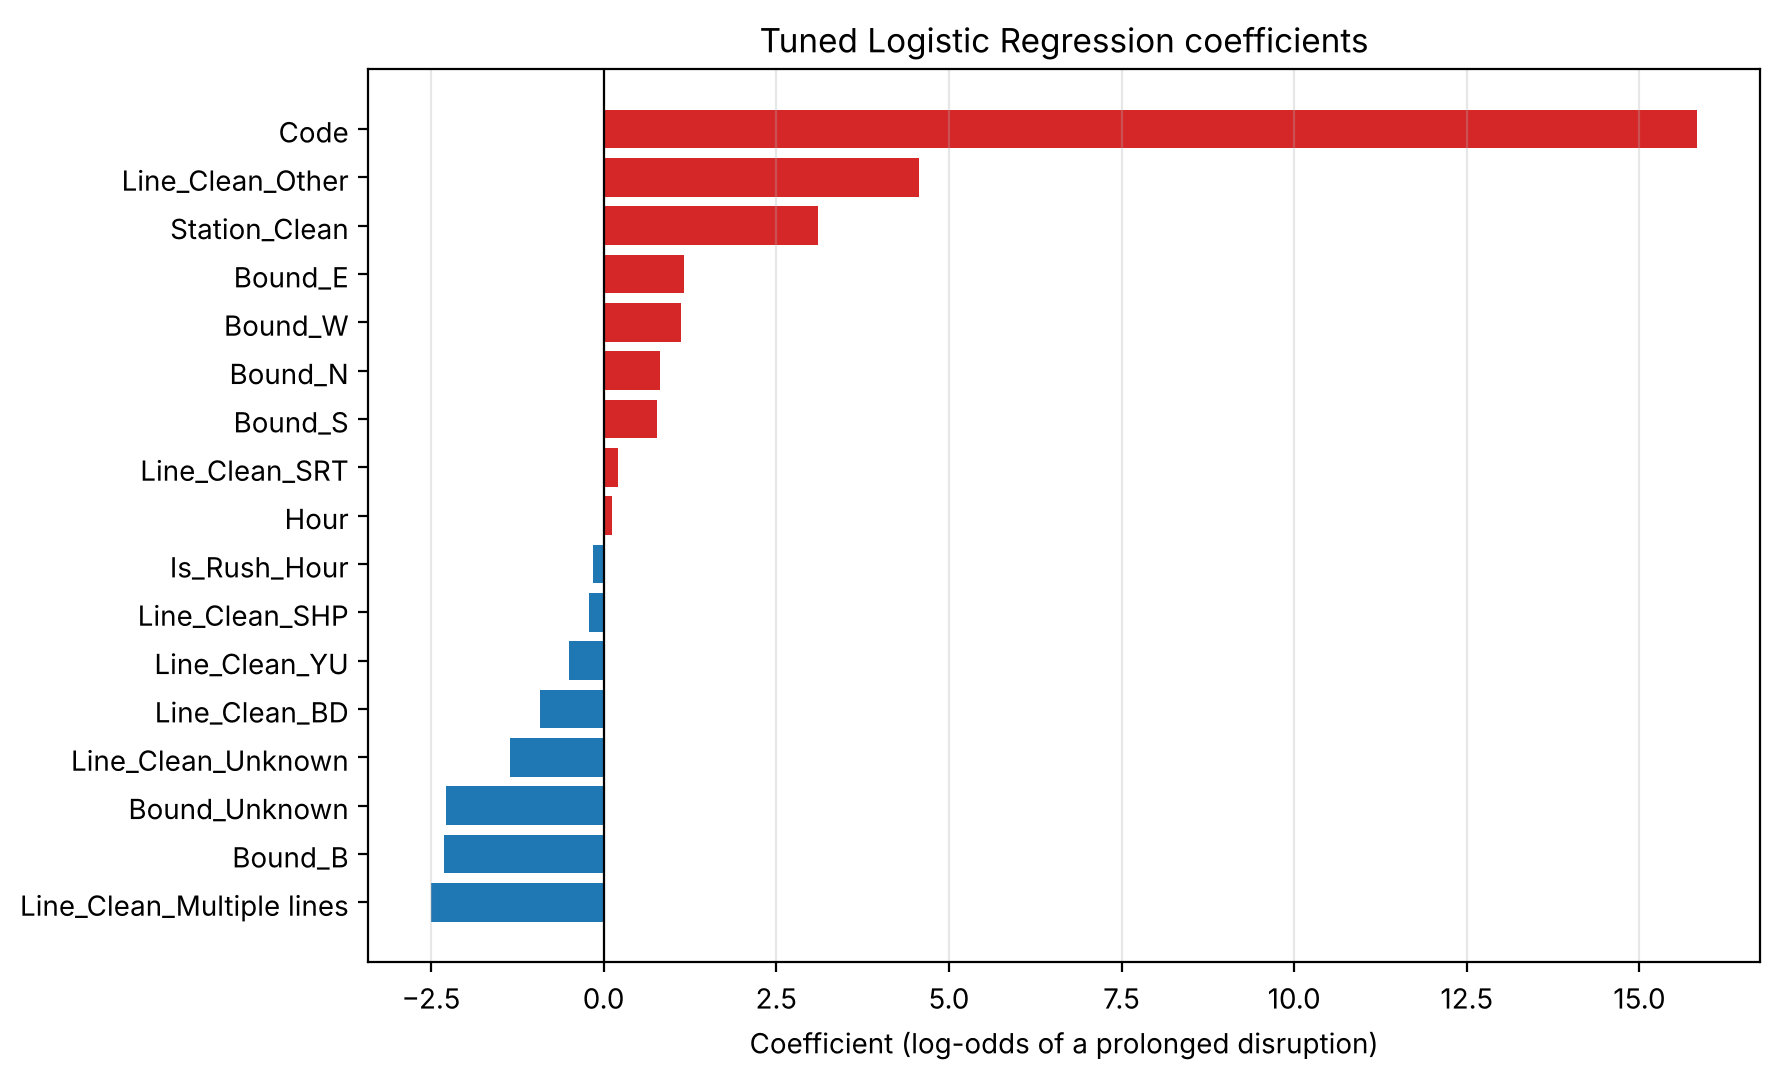

Encoded Code values range from 0.000 to 0.763, so the Code coefficient of 15.8 moves the log-odds by up to 12.1.
Number of non-zero coefficients: 17 of 17


In [24]:
# What the fitted Logistic Regression uses (uncalibrated tuned pipeline refitted on all training data)
fitted_lr = clone(best_lr).fit(X_train, y_train)
coefs = pd.Series(fitted_lr.named_steps["model"].coef_[0],
                  index=fitted_lr.named_steps["preprocessor"].get_feature_names_out()).sort_values()
coefs.index = [name.split("__", 1)[1] for name in coefs.index]

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(coefs.index, coefs.values, color=np.where(coefs.values >= 0, "#d62728", "#1f77b4"))
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("Coefficient (log-odds of a prolonged disruption)")
ax.set_title("Tuned Logistic Regression coefficients")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.show()

te = fitted_lr.named_steps["preprocessor"].named_transformers_["high_card"]
code_rates = pd.Series(te.encodings_[0], index=te.categories_[0])
print("Encoded Code values range from "
      f"{code_rates.min():.3f} to {code_rates.max():.3f}, so the Code coefficient of {coefs['Code']:.1f} "
      f"moves the log-odds by up to {coefs['Code'] * (code_rates.max() - code_rates.min()):.1f}.")
print(f"Number of non-zero coefficients: {(coefs != 0).sum()} of {len(coefs)}")

### What the error analysis shows

#### Performance by subgroup

- The two main lines are treated alike. Bloor-Danforth and Yonge-University have recall of 0.50 and 0.48, precision of 0.22 and 0.21, and about 7% of incidents flagged.
- The two small lines are over-flagged. On Sheppard, 18% of incidents are flagged, and on the Scarborough line 47% are. Recall there is high (0.69 and 0.96) and precision is lower (0.19 and 0.16). The model also overestimates risk on both: mean predicted 0.060 against 0.049 actual on Sheppard, and 0.088 against 0.077 on Scarborough. In practice this means shuttle requests would be triggered far more readily on those lines.
- The Scarborough numbers describe a line that no longer runs. Almost all of its incidents are from before the July 2023 derailment that ended service on Line 3, so the model has learned patterns for a line it will never score again.
- Night is the weakest period. PR-AUC between midnight and 5 am is 0.19, against 0.31 at midday, and night precision is the lowest of any period (0.17). Late night is when Milestones 1 and 2 said a missed disruption hurts most, because replacement buses are scarce.
- Rush hour is slightly worse than off-peak (PR-AUC 0.23 against 0.28). During the PM peak the model underestimates risk: mean predicted 0.030 against 0.035 actual.

#### Which incidents are missed

Four codes account for 70% of all missed prolonged disruptions: Passenger Other (SUO), Disorderly Patron (SUDP), Injured or Ill Customer, Medical Aid Refused (MUIR) and Assault / Patron Involved (SUAP). These are high-volume codes with low prolonged rates. Disorderly Patron has 5,502 incidents, of which 156 (2.8%) became prolonged. The model gives them probabilities of about 2 to 3%, well below the threshold, and misses 154 of the 156. Nothing known at onset separates the disorderly-patron incident that clears in two minutes from the one that takes forty.

#### Which incidents are false alarms

Two codes produce 54% of false alarms: Unauthorized at Track Level (SUUT, 35%) and Injured or Ill Customer, Transported (MUI, 19%). Their prolonged rates are 17% and 20%, above the threshold, so the model flags nearly every incident with those codes. It is right about one time in five and cannot tell which one.

Both error types have the same cause. The model has largely become a rule that says "flag these codes, ignore those", and its errors are the incidents that behave differently from their code's average.

#### Severity of the errors

- Recall rises with the length of the delay: 41% for incidents of 16 to 20 minutes, 53% for 21 to 30, 61% for 31 to 60, and 77% for incidents over an hour. The misses are concentrated among borderline cases just above the 15-minute line, where a shuttle would have helped least. The long disruptions are caught more often.
- False alarms are spread across all delay lengths. 30% of them had no delay at all, and only 15% were near misses of 11 to 15 minutes. A false alarm is therefore usually a clear mistake.

#### What the model uses

The coefficient plot agrees with the ablation. The target-encoded `Code` has by far the largest coefficient (15.8), and across the range of encoded code rates it can move the log-odds by 12. `Bound` also matters: a missing or "B" bound has a coefficient near -2.3, while the four compass directions sit between +0.8 and +1.2.

That `Bound` effect needs a caution. Among training incidents with no bound recorded, 17 of 14,389 (0.1%) were prolonged, against 5.0% where a bound was recorded. A blank bound is close to a marker for "this entry was not a train delay". If dispatchers fill in the bound only once an incident has turned into a real delay, then part of the outcome is leaking into the feature, and that part of the model's skill would not exist at onset. We cannot settle this from the data. The ablation shows the model still reaches a PR-AUC of 0.261 without `Bound`, so the conclusions do not rest on it.

## Analysis of biases and deployment risks

The risks below were identified during modelling. Each is now tied to what Phases 4 to 6 measured.

### 1. Reporting bias in `Bound`

About 36% of `Bound` values are missing, and the missingness follows the incident type. We impute "Unknown" and the model uses it: incidents without a bound are almost never flagged, and 0.1% of them are prolonged against 5.0% of the rest. The model has learned a logging habit. If that habit changes, or if the bound is entered later than the moment of prediction, this signal disappears or turns out to have been leakage. Before deployment, TTC control staff would need to confirm when the field is filled in.

### 2. Temporal and concept drift

The model learns historical rates per code and station from 2023 and 2024. The split by year in Phase 6 measured the cost: PR-AUC fell from 0.265 to 0.232 when 2023 was used to predict 2024. Line 3 Scarborough is a concrete case. It stopped running in July 2023, yet it is still part of the training data and holds the highest flag rate of any line. New signalling, new rolling stock or a revision of the code list would have similar effects.

### 3. Feedback loop

If dispatchers act on the model, the outcome it was trained on changes. A shuttle deployed early does not shorten the recorded subway delay, but any intervention that does shorten it makes the model's alert look like a false alarm in the next training set. Retraining on post-deployment data would then teach the model to stop flagging the incidents where acting worked. Logging whether each alert was acted on is the minimum needed to correct for this later.

### 4. Asymmetric cost of errors

A missed prolonged disruption strands subway passengers. A false alarm takes buses away from surface routes. We weighted recall more heavily through the F2 score, and the resulting operating point is 158 caught, 157 missed and 609 false alarms on the test set. Whether nearly four unnecessary deployments per useful one is acceptable is a decision for the TTC. The burden of false alarms falls on bus riders in the neighbourhoods the buses are pulled from, a group that is not represented anywhere in our data.

### 5. Unequal performance across lines and times

Milestone 2 asked that errors not concentrate on particular lines or times. They do, to a degree. Sheppard and Scarborough incidents are flagged about 2.5 and 6.5 times as often as incidents on the two main lines, and the model is least accurate at night. A single threshold applied everywhere would over-deploy on the small lines and give the weakest guidance in the hours when a wrong call costs the most.

### 6. Rare and extreme events

The longest delays in the data exceed ten hours. The model catches 77% of incidents over an hour, better than its average, but it only predicts whether 15 minutes is exceeded and says nothing about how long a disruption will last. Unprecedented events have no history to learn from, so a human override has to remain part of any deployment.

## Phase 7: Analytical reflection

### Does the final model generalise?

Within the 2023 to 2024 data it generalises as well as its inputs allow. PR-AUC is 0.295 on training rows, 0.265 in cross-validation and 0.245 on the test set, recall and precision at the threshold are nearly identical across the three, and calibration holds on unseen data. Two results limit that claim. Repeated cross-validation ranges from 0.23 to 0.33, so any single estimate is uncertain by several points. And when the model predicts 2024 from 2023, PR-AUC is 0.232, which is the fairest estimate of how it would perform in use. The model generalises across incidents from the same period better than it generalises forward in time.

### Structural weaknesses

The main weakness is the information available at onset. Removing `Code` takes PR-AUC from 0.278 to 0.073, and no other feature moves it by more than 0.016. The learning curve is flat, three tuned model families tie at 0.276 to 0.278, and 70% of missed disruptions sit in four high-volume codes whose incidents the model cannot tell apart. Taken together, these results say the ceiling is set by the features. A better algorithm or more rows of the same data would not lift it.

Two assumptions in the experimental design are also weak. We treat `Code` and `Bound` as known at onset, but the log records their final values. An incident first reported as "Passenger Other" may be recoded once its cause is understood, and `Bound` may be filled in only for real delays. If so, our scores overstate what a live system would achieve. The second is the target itself: 64% of logged incidents have zero delay, so part of what the model learns is to recognise entries that were never delays.

### Real-world deployment risks

At the chosen threshold the model raises about four false alarms for every prolonged disruption it catches and still misses half of them. The probabilities it produces are mostly between 5% and 25%, so the 50% and 80% triggers we proposed in Milestone 2 cannot be used. Deployed as an automatic trigger, it would either divert buses constantly or be ignored. Its realistic role is to rank concurrent incidents for a dispatcher's attention, with a human making the call. The bias section above adds drift (a closed line still shapes the model), a feedback loop once dispatchers act on alerts, and higher flag rates on the smaller lines.

### Was augmentation beneficial?

No. Across four resampling methods and two model types, none improved PR-AUC beyond fold noise, and two made it worse (SMOTENC with Logistic Regression, SMOTE with XGBoost). Balancing only moved the scores so that a 0.50 cut-off became usable, at the cost of probabilities ten times too high. Threshold selection on the original data reached the same F2 with calibration intact. Our data has 1,265 real positives, which is enough for a six-feature model to learn from. The difficulty is that positives and negatives overlap in feature space, and synthetic rows drawn from the same overlapping region add nothing. Augmentation would be worth revisiting only for a much rarer target, such as delays over an hour.

### Future improvements

1. Add information that exists at onset but is not in this log: train headways and passenger load at the time, weather, planned track work, and whether another incident is already open on the line. The error analysis shows the missing signal is about what distinguishes incidents within a code, and these are the candidates.
2. Model how long the incident has already lasted. Predicting at minute 0 is the hardest version of the problem. A survival model, or a classifier re-run at 3, 5 and 10 minutes with elapsed time as a feature, would let the probability rise as an incident drags on, which is how a dispatcher reasons.
3. Replace the random split with rolling time-based validation, and retrain on a schedule with monitoring of calibration and base rate.
4. Verify with TTC staff when `Code` and `Bound` are entered, and rebuild the features from the first logged values if they differ from the final ones.
5. Set thresholds per line and time of day from explicit cost estimates for a stranded train and a diverted bus, in place of the single F2-based threshold.
6. Build the secondary regression task from Milestone 2 (expected delay in minutes), which a shuttle decision also needs and which this milestone did not cover.